# M3 — Time-series modelling, frozen-test evaluation and Phase 1 checks
**Project:** Delhi-NCR high-pollution-day forecasting (PM2.5 ≥ 120.5 µg/m³ ⇔ PM-only AQI > 300) · **Member 3** · Review 2, Unit 3 (Method 1: time-series analysis)

**What this notebook does**

1. Loads M2's `p2_ts_inputs.csv`, `p2_series.csv` and the Phase 1 `m4_full_engineered.csv`, and runs integrity checks.
2. Builds **direct multi-horizon** datasets: at origin day *t* we forecast PM2.5 on days *t+1, t+2, t+3*.
3. Fits baselines, **SARIMAX** (log PM2.5, Fourier seasonal terms, optional lagged weather) and a **direct gradient-boosting regressor per horizon**.
4. Picks between them by **time-ordered validation** (three fixed expanding folds: 2022, 2023, 2024). The test set is not touched until the choice is made.
5. Scores the **frozen test set** (Jan 2025 – Sep 2026): MAE / RMSE per horizon, winter-only scores, alert precision / recall at 120.5, block-bootstrap uncertainty.
6. Runs the **Phase 1 checks**: rolling-feature leakage, single-feature AUC, same-day-weather ablation, ban-list assertion.

**Rules this notebook enforces**

* The target is never imputed. Days with no target stay `NaN` and are simply not scored.
* No model sees a target dated on or after the start of its validation / test window.
* Weather is used only as **observed at the origin day** (lagged relative to the target day). A "same-day weather" model would be a *perfect forecast* of weather, so it is run only as a clearly labelled **upper bound**.
* The same rows are scored for every model within a horizon, so the comparison is like-for-like.

In [1]:
import warnings, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

SEED = 42
THRESH = 120.5                      # PM2.5 (ug/m3) at which PM-only AQI exceeds 300
HORIZONS = [1, 2, 3]
TRAIN_END = pd.Timestamp("2024-12-31")
TEST_START = pd.Timestamp("2025-01-01")
VAL_YEARS = [2022, 2023, 2024]      # fixed expanding-origin validation folds (same as M2's cv_fold column)
BOOT_B, BOOT_BLOCK = 1000, 7        # moving-block bootstrap for the test set

DATA = Path(".")
OUT = Path("m3_outputs"); OUT.mkdir(exist_ok=True)

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 1. Load and integrity checks
Dates must be ISO (`YYYY-MM-DD`). If a file has day-first text dates (`01-01-2018`) `parse_dates` leaves strings behind and the assertions below fail loudly, which is intended.

In [2]:
ts  = pd.read_csv(DATA / "p2_ts_inputs.csv", parse_dates=["date"]).set_index("date")
ser = pd.read_csv(DATA / "p2_series.csv",    parse_dates=["date"]).set_index("date")
m4  = pd.read_csv(DATA / "m4_full_engineered.csv", parse_dates=["date"]).set_index("date")

for name, d in [("p2_ts_inputs", ts), ("p2_series", ser), ("m4_full_engineered", m4)]:
    assert pd.api.types.is_datetime64_any_dtype(d.index), f"{name}: dates not parsed (day-first strings?)"
    assert d.index.is_monotonic_increasing and d.index.is_unique, name
    assert (d.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all(), f"{name}: gaps in calendar"
assert ts.index.equals(ser.index) and ts.index.equals(m4.index), "files cover different dates"
ts = ts.asfreq("D"); ser = ser.asfreq("D"); m4 = m4.asfreq("D")

y = ts["pm25_target"]
assert np.allclose(y.fillna(-1), ser["pm25_target"].fillna(-1)), "target differs between p2 files"
assert np.allclose(y.fillna(-1), m4["pm25_target"].fillna(-1)), "target differs from Phase 1 file"
assert (ser.loc[y.isna(), "high_risk"].isna()).all(), "high_risk must stay NaN where the target is missing"
assert ((y >= THRESH).astype(float)[y.notna()] == ser.loc[y.notna(), "high_risk"]).all(), "label != PM2.5 >= 120.5"
assert (y.dropna() > 0).all() and (ts["pm25_input"].dropna() > 0).all()
assert ts.loc[ts.input_filled == 0, "pm25_input"].equals(y[ts.input_filled == 0]) or \
       np.allclose(ts.loc[ts.input_filled == 0, "pm25_input"].fillna(-1), y[ts.input_filled == 0].fillna(-1))

print(f"{len(ts)} days  {ts.index.min().date()} -> {ts.index.max().date()}")
print("target_source:", ser["target_source"].value_counts().to_dict())
print(f"target missing (never imputed): {y.isna().sum()} days | observed: {y.notna().sum()} | high-risk days: {int((y >= THRESH).sum())}")
print("period:", ts["period"].value_counts().to_dict())
print("input_filled days (<=2-day forward fill, features only):", int(ts.input_filled.sum()),
      "| input still missing:", int(ts.pm25_input.isna().sum()))
print("cv_fold in file:", ts["cv_fold"].value_counts().sort_index().to_dict())

3195 days  2018-01-01 -> 2026-09-30
target_source: {'reference': 2836, 'missing': 272, 'city_fallback': 87}
target missing (never imputed): 272 days | observed: 2923 | high-risk days: 792
period: {'train': 2557, 'test': 638}
input_filled days (<=2-day forward fill, features only): 166 | input still missing: 106
cv_fold in file: {1.0: 365, 2.0: 365, 3.0: 366}


## 2. Direct multi-horizon datasets
For horizon *h* every row is an **origin day *t***. Inputs are everything known at the end of day *t*; the target is PM2.5 on day *t+h*.

* **Autoregressive inputs**: log PM2.5 at *t* … *t−7* (forward-filled ≤ 2 days, `input_age` says how stale), 3- and 7-day means, one-day change.
* **Weather observed at the origin day** (temperature, humidity, wind, pressure, rain, cloud, dew-point, gust): value at *t*, at *t−1*, 3-day mean, pressure and wind change. These are *lagged relative to the target day*, so no weather forecast is assumed.
* **Calendar of the target day** (known in advance): Fourier terms, month, weekday, Diwali distance, festival window.
* **Rows** are kept only if the origin input exists and the target on day *t+h* was observed. This is the same row set for every model at that horizon.
* **Split by target date**: train ≤ 2024-12-31, test ≥ 2025-01-01.

In [3]:
WEATHER = ["temp_mean", "humidity_mean", "wind_speed_mean", "pressure_mean", "precip_sum",
           "cloud_mean", "dewpoint_mean", "wind_gust_max"]
W = m4[WEATHER]
assert W.notna().all().all(), "weather has gaps"
FOU_ALL = [f"fourier_{f}{k}" for k in range(1, 7) for f in ("sin", "cos")]

# ---------- features known at the end of the origin day ----------
F0 = pd.DataFrame(index=ts.index)
F0["lpm_0"] = np.log(ts["pm25_input"])
for k in range(1, 8):
    F0[f"lpm_{k}"] = np.log(ts[f"pm25_input_lag{k}"])
F0["lpm_mean3"] = F0[["lpm_0", "lpm_1", "lpm_2"]].mean(axis=1)
F0["lpm_mean7"] = F0[[f"lpm_{k}" for k in range(7)]].mean(axis=1)
F0["lpm_diff1"] = F0["lpm_0"] - F0["lpm_1"]
F0["input_age"] = ts["input_age_days"]
WX_COLS = []
for c in WEATHER:
    F0[f"{c}_t0"] = W[c]; F0[f"{c}_t1"] = W[c].shift(1); F0[f"{c}_mean3"] = W[c].rolling(3).mean()
    WX_COLS += [f"{c}_t0", f"{c}_t1", f"{c}_mean3"]
F0["pressure_chg"] = W["pressure_mean"] - W["pressure_mean"].shift(1)
F0["wind_chg"] = W["wind_speed_mean"] - W["wind_speed_mean"].shift(1)
WX_COLS += ["pressure_chg", "wind_chg"]
AR_COLS = [c for c in F0.columns if c not in WX_COLS]

# ---------- calendar of the TARGET day (known in advance) ----------
CAL = pd.concat([ts[FOU_ALL], ts[["month", "day_of_week"]],
                 m4[["is_weekend", "days_from_diwali", "is_festival_window"]]], axis=1)

def build(h):
    X = F0.copy()
    for c in CAL.columns:
        X[f"{c}_tgt"] = CAL[c].shift(-h)
    for c in WEATHER:                        # ORACLE ONLY: weather on the target day = a perfect forecast
        X[f"{c}_ORACLE"] = W[c].shift(-h)
    X["target_date"] = X.index + pd.Timedelta(days=h)
    X["y"] = y.shift(-h)
    X["is_winter_tgt"] = ts["is_winter_nov_jan"].shift(-h)
    X["pm_in"] = ts["pm25_input"]
    X["pm_seas7"] = ts[f"pm25_input_lag{7 - h}"]          # value 7 days before the target day
    return X[X["pm_in"].notna() & X["y"].notna()].copy()

D = {h: build(h) for h in HORIZONS}
CAL_TGT = [f"{c}_tgt" for c in CAL.columns]
ORACLE = [f"{c}_ORACLE" for c in WEATHER]
GB_COLS = AR_COLS + WX_COLS + CAL_TGT
GB_COLS_NOWX = AR_COLS + CAL_TGT
GB_COLS_ORACLE = GB_COLS + ORACLE
assert not any("ORACLE" in c for c in GB_COLS)

rows = []
for h, d in D.items():
    tr, te = d[d.target_date <= TRAIN_END], d[d.target_date >= TEST_START]
    rows.append({"horizon": h, "train rows": len(tr), "test rows": len(te),
                 "test high-risk days": int((te.y >= THRESH).sum()),
                 "test winter rows": int((te.is_winter_tgt == 1).sum()),
                 "test winter high-risk": int(((te.is_winter_tgt == 1) & (te.y >= THRESH)).sum())})
pd.DataFrame(rows).set_index("horizon")

,train rows,test rows,test high-risk days,test winter rows,test winter high-risk
horizon,,,,,
1,2268,635,128,121,106
2,2258,635,128,121,106
3,2254,635,128,121,106


**Fixed validation scheme.** Fold *Y* trains on rows whose **target date** is before 1 Jan *Y* and validates on rows whose target date falls in year *Y* (Y = 2022, 2023, 2024). Climatology, the damped-anomaly coefficient, SARIMAX parameters and gradient-boosting fits are all re-estimated inside each fold, so validation never sees its own future.

In [4]:
def fold_masks(d, Y):
    tr = d["target_date"] < pd.Timestamp(f"{Y}-01-01")
    va = (d["target_date"] >= pd.Timestamp(f"{Y}-01-01")) & (d["target_date"] <= pd.Timestamp(f"{Y}-12-31"))
    return tr.values, va.values

print(pd.DataFrame({f"h={h}": {f"val {Y} (n, train n)": f"{fold_masks(d, Y)[1].sum()}, {fold_masks(d, Y)[0].sum()}"
                              for Y in VAL_YEARS} for h, d in D.items()}))

                             h=1        h=2        h=3
val 2022 (n, train n)  350, 1256  350, 1250  350, 1247
val 2023 (n, train n)  307, 1606  304, 1600  303, 1597
val 2024 (n, train n)  355, 1913  354, 1904  354, 1900


## 3. Metrics and uncertainty helpers
Forecasts are made on the log scale and back-transformed with `exp()`, so they are *median* forecasts (the right target for MAE; RMSE at the peaks will be somewhat pessimistic). Uncertainty on the test set uses a **moving-block bootstrap** (7-day blocks) because neighbouring days are strongly dependent.

In [5]:
def reg_metrics(y_true, y_pred):
    e = np.asarray(y_pred, float) - np.asarray(y_true, float)
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean())}

def alert_metrics(y_true, y_pred, thr=THRESH):
    A, Y = np.asarray(y_pred) >= thr, np.asarray(y_true) >= THRESH
    tp, fp, fn, tn = (A & Y).sum(), (A & ~Y).sum(), (~A & Y).sum(), (~A & ~Y).sum()
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * prec * rec / (prec + rec) if tp > 0 else (0.0 if (tp + fp + fn) else np.nan)
    return {"precision": prec, "recall": rec, "F1": f1, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}

def block_idx(n, block=BOOT_BLOCK, B=BOOT_B, seed=SEED):
    rng = np.random.default_rng(seed)
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, max(n - block, 1), size=(B, nb))
    return (starts[:, :, None] + np.arange(block)).reshape(B, -1)[:, :n]

def boot_stats(y_true, y_pred, idx, thr=THRESH):
    yt, yp = np.asarray(y_true)[idx], np.asarray(y_pred)[idx]
    e = yp - yt
    A, Y = yp >= thr, yt >= THRESH
    tp, fp, fn = (A & Y).sum(1), (A & ~Y).sum(1), (~A & Y).sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        prec, rec = tp / (tp + fp), tp / (tp + fn)
        f1 = 2 * tp / (2 * tp + fp + fn)
    return {"MAE": np.abs(e).mean(1), "RMSE": np.sqrt((e ** 2).mean(1)),
            "precision": prec, "recall": rec, "F1": f1}

def ci(a, lo=2.5, hi=97.5):
    a = a[np.isfinite(a)]
    return (np.percentile(a, lo), np.percentile(a, hi)) if len(a) else (np.nan, np.nan)

## 4. Baselines
All four are fitted **only on training data of the fold/test they are scored on**.

| Baseline | Forecast for day *t+h* |
|---|---|
| Persistence | PM2.5 at *t* |
| Seasonal naive (7-day) | PM2.5 seven days before the target day |
| Climatology | exp of a 6-harmonic Fourier fit to log PM2.5 (training years only) |
| Damped-anomaly persistence | climatology(*t+h*) + φₕ·(log PM2.5ₜ − climatology(*t*)), φₕ fitted on training rows |

In [6]:
def climatology(train_end):
    m = (ts.index <= train_end) & y.notna().values
    Xc = np.column_stack([np.ones(m.sum()), ts.loc[m, FOU_ALL].values])
    beta = np.linalg.lstsq(Xc, np.log(y[m].values), rcond=None)[0]
    full = np.column_stack([np.ones(len(ts)), ts[FOU_ALL].values]) @ beta
    return pd.Series(full, index=ts.index)

def baseline_preds(h, d, train_rows, train_end):
    clim = climatology(train_end)
    c_tgt = clim.reindex(d["target_date"]).values
    c_org = clim.reindex(d.index).values
    anom = d["lpm_0"].values - c_org
    tgt_anom = np.log(d["y"].values) - c_tgt
    phi = (anom[train_rows] * tgt_anom[train_rows]).sum() / (anom[train_rows] ** 2).sum()
    return pd.DataFrame({
        "Persistence": d["pm_in"].values,
        "Seasonal naive (7d)": d["pm_seas7"].values,
        "Climatology": np.exp(c_tgt),
        "Damped-anomaly persistence": np.exp(c_tgt + phi * anom)}, index=d.index), phi

val_rows = []; VALPRED = {}          # VALPRED[(model, h)] -> Series of validation forecasts (pooled folds)
for h, d in D.items():
    for Y in VAL_YEARS:
        tr, va = fold_masks(d, Y)
        bp, phi = baseline_preds(h, d, tr, pd.Timestamp(f"{Y-1}-12-31"))
        for name in bp:
            p = bp.loc[va, name]
            val_rows.append({"horizon": h, "fold": Y, "model": name, "n": int(va.sum()), **reg_metrics(d.loc[va, "y"], p)})
            VALPRED.setdefault((name, h), []).append(p)
val_base = pd.DataFrame(val_rows)
val_base.groupby(["horizon", "model"])[["MAE", "RMSE"]].mean().round(1).unstack(0)

MAE              RMSE            
horizon                        1     2     3     1     2     3
model                                                         
Climatology                 28.4  28.4  28.5  43.6  43.6  43.7
Damped-anomaly persistence  20.8  25.6  26.7  33.6  39.8  41.5
Persistence                 23.1  30.1  32.5  37.3  47.5  50.8
Seasonal naive (7d)         38.4  38.4  38.4  56.1  56.1  56.1

## 5. SARIMAX on log PM2.5
**Specification.** `log PM2.5 ~ ARMA errors + Fourier seasonal terms (+ weather lagged by h days)`.

* Yearly seasonality is carried by Fourier terms (a 365-day seasonal ARIMA is not estimable on daily data); one candidate also adds a weekly seasonal AR term.
* Missing days stay `NaN` in the series; the Kalman filter skips them. Nothing is imputed.
* The weather candidates use weather **lagged by h days**: the exogenous value for target day *s* is the weather observed on day *s−h*, so forecasting day *t+h* needs only weather up to day *t*. No weather forecast is assumed.
* The h-step forecast is read from the filtered state at the origin day (parameters fixed from the training window). The helper is checked against statsmodels' own `get_prediction(dynamic=0)` before use.

In [7]:
LOGY = np.log(y)
SX_START = ts.index[7]                 # first 7 days dropped so lagged exog exist
SARIMAX_CFGS = {
    "ARMA(1,0,1)+F3":          dict(order=(1, 0, 1), seasonal=(0, 0, 0, 0), K=3, wx=False),
    "ARMA(2,0,1)+F3":          dict(order=(2, 0, 1), seasonal=(0, 0, 0, 0), K=3, wx=False),
    "ARMA(2,0,1)+F6":          dict(order=(2, 0, 1), seasonal=(0, 0, 0, 0), K=6, wx=False),
    "SARMA(2,0,1)(1,0,0)7+F3": dict(order=(2, 0, 1), seasonal=(1, 0, 0, 7), K=3, wx=False),
    "ARMA(2,0,1)+F3+wx":       dict(order=(2, 0, 1), seasonal=(0, 0, 0, 0), K=3, wx=True),
    "ARMA(2,0,1)+F6+wx":       dict(order=(2, 0, 1), seasonal=(0, 0, 0, 0), K=6, wx=True),
}

# nested parents: a child must never fit worse than its parent, so we warm-start from the parent's parameters
PARENT = {"ARMA(2,0,1)+F3": "ARMA(1,0,1)+F3", "ARMA(2,0,1)+F6": "ARMA(2,0,1)+F3",
          "SARMA(2,0,1)(1,0,0)7+F3": "ARMA(2,0,1)+F3", "ARMA(2,0,1)+F3+wx": "ARMA(2,0,1)+F3",
          "ARMA(2,0,1)+F6+wx": "ARMA(2,0,1)+F6"}

def hstep(res, hmax):
    # h-step-ahead mean forecasts from every origin, using the filtered state a_{t|t} (fixed parameters)
    fr = res.filter_results
    a = fr.filtered_state; n = a.shape[1]
    T, Z, c, d0 = fr.transition, fr.design, fr.state_intercept, fr.obs_intercept
    assert T.shape[2] == 1 and Z.shape[2] == 1
    T0, Z0 = T[:, :, 0], Z[:, :, 0]
    def sh(arr, k):
        if arr.shape[1] == 1: return np.repeat(arr, n, 1)
        return arr[:, np.minimum(np.arange(n) + k, arr.shape[1] - 1)]
    out = np.full((n, hmax), np.nan); A = a.copy()
    for j in range(1, hmax + 1):
        A = T0 @ A + sh(c, j - 1)
        out[:, j - 1] = ((Z0 @ A) + sh(d0, j))[0]
        out[n - j:, j - 1] = np.nan
    return out

SX_LOG, _sx_cache = [], {}
def sarimax_forecasts(name, train_end, h=None):
    # log-scale forecasts for horizon(s) at every origin date. Weather configs need h (exog lag).
    cfg = SARIMAX_CFGS[name]
    key = (name, train_end, h if cfg["wx"] else 0)
    if key in _sx_cache: return _sx_cache[key]
    ex = ts[FOU_ALL[:2 * cfg["K"]]].copy()
    if cfg["wx"]:
        Wl = W.shift(h); Wl.columns = [f"{c}_lag{h}" for c in W.columns]
        ex = pd.concat([ex, Wl], axis=1)
    win = (ex.index >= SX_START) & (ex.index <= train_end)
    if cfg["wx"]:
        wc = list(Wl.columns); mu, sd = ex.loc[win, wc].mean(), ex.loc[win, wc].std()
        ex[wc] = (ex[wc] - mu) / sd
    t0 = time.time()
    mod = SARIMAX(LOGY[win], exog=ex[win], order=cfg["order"], seasonal_order=cfg["seasonal"], trend="c")
    start = None; parent_llf = None
    if name in PARENT:
        pname = PARENT[name]
        pres = sarimax_forecasts(pname, train_end, h if SARIMAX_CFGS[pname]["wx"] else None)[1]
        sp = pd.Series(0.0, index=mod.param_names)
        for k in pres.params.index:
            if k in sp.index: sp[k] = pres.params[k]
        start, parent_llf = sp.values, pres.llf
    res = mod.fit(start_params=start, disp=False, maxiter=300)
    conv = bool(res.mle_retvals.get("converged", True)) if res.mle_retvals else True
    full = res.apply(LOGY[SX_START:], exog=ex[SX_START:], refit=False)
    hs = [h] if cfg["wx"] else HORIZONS
    F = hstep(full, max(hs))
    out = pd.DataFrame(F, index=ts.index[7:], columns=[1, 2, 3][:max(hs)]).reindex(ts.index)
    SX_LOG.append({"config": name, "train_end": train_end.date(), "h": h, "converged": conv,
                   "llf": round(res.llf, 1), "parent_llf": None if parent_llf is None else round(parent_llf, 1),
                   "AIC": round(res.aic, 1), "seconds": round(time.time() - t0, 1)})
    _sx_cache[key] = (out, res)
    return _sx_cache[key]

# ---- sanity check of the h-step helper against statsmodels on a few origins ----
_, r_chk = sarimax_forecasts("ARMA(2,0,1)+F3", pd.Timestamp("2023-12-31"))
full_chk = r_chk.apply(LOGY[SX_START:], exog=ts[FOU_ALL[:6]][SX_START:], refit=False)
Fchk = hstep(full_chk, 3)
for t in (500, 2000, 2500):
    gp = full_chk.get_prediction(start=t + 1, end=t + 3, dynamic=0).predicted_mean.values
    assert np.allclose(Fchk[t], gp, atol=1e-6), (t, Fchk[t], gp)
print("h-step helper matches statsmodels get_prediction(dynamic=0)")

h-step helper matches statsmodels get_prediction(dynamic=0)


In [8]:
t0 = time.time(); sx_val = []
for name, cfg in SARIMAX_CFGS.items():
    for h in HORIZONS:
        for Y in VAL_YEARS:
            te_end = pd.Timestamp(f"{Y-1}-12-31")
            F, _ = sarimax_forecasts(name, te_end, h if cfg["wx"] else None)
            d = D[h]; tr, va = fold_masks(d, Y)
            p = pd.Series(np.exp(F[h].reindex(d.index).values), index=d.index)[va]
            sx_val.append({"horizon": h, "fold": Y, "model": f"SARIMAX {name}", "n": int(va.sum()),
                           **reg_metrics(d.loc[va, "y"], p)})
            VALPRED.setdefault((f"SARIMAX {name}", h), []).append(p)
sx_val = pd.DataFrame(sx_val)
print(f"SARIMAX validation grid done in {time.time() - t0:.0f}s; non-converged fits: "
      f"{sum(not r['converged'] for r in SX_LOG)} of {len(SX_LOG)}")
sxl = pd.DataFrame(SX_LOG)
bad = sxl[sxl.parent_llf.notna() & (sxl.llf < sxl.parent_llf - 1.0)]
assert bad.empty, f"nested model fits worse than its parent (optimiser failure):\n{bad}"
print("nesting check passed: every child model has log-likelihood >= its parent on the same training window")
sx_val.groupby(["horizon", "model"])[["MAE", "RMSE"]].mean().round(1).unstack(0)

SARIMAX validation grid done in 590s; non-converged fits: 0 of 30
nesting check passed: every child model has log-likelihood >= its parent on the same training window


MAE              RMSE            
horizon                             1     2     3     1     2     3
model                                                              
SARIMAX ARMA(1,0,1)+F3           21.2  26.3  28.0  34.2  41.4  44.1
SARIMAX ARMA(2,0,1)+F3           21.1  26.3  28.0  34.2  41.5  44.1
SARIMAX ARMA(2,0,1)+F3+wx        20.7  26.3  27.9  34.1  41.4  44.1
SARIMAX ARMA(2,0,1)+F6           20.7  25.7  26.9  33.4  39.9  41.9
SARIMAX ARMA(2,0,1)+F6+wx        20.3  25.6  26.9  33.2  40.0  41.9
SARIMAX SARMA(2,0,1)(1,0,0)7+F3  21.1  26.2  27.9  34.1  41.4  44.0

## 6. Direct gradient-boosting regressor (one model per horizon)
`HistGradientBoostingRegressor` on **log PM2.5 at *t+h***, squared-error loss, with a small hyper-parameter grid scored on the same three validation folds. The feature set is the one defined in section 2 (autoregressive + weather observed at the origin + target-day calendar). Two variants are kept for interpretation, using the winning hyper-parameters of the main model:

* **GB, no weather**: autoregressive + calendar only (does weather add anything beyond PM2.5 history?)
* **GB + perfect-forecast weather (ORACLE)**: adds the weather of the *target day*. **Not deployable**; it is the ceiling if weather forecasts were perfect, and the same-day-weather ablation for Phase 2.

In [9]:
GB_GRID = [dict(learning_rate=lr, max_depth=md_, max_iter=it, min_samples_leaf=msl, l2_regularization=1.0)
           for lr in (0.03, 0.08) for md_ in (3, 5) for it in (150, 400) for msl in (20, 40)]

def gb_fit_predict(Xtr, ytr, Xte, params):
    m = HistGradientBoostingRegressor(loss="squared_error", random_state=SEED, **params)
    m.fit(Xtr, np.log(ytr)); return np.exp(m.predict(Xte)), m

t0 = time.time(); gb_val = []
for h, d in D.items():
    for gi, params in enumerate(GB_GRID):
        for Y in VAL_YEARS:
            tr, va = fold_masks(d, Y)
            p, _ = gb_fit_predict(d.loc[tr, GB_COLS], d.loc[tr, "y"], d.loc[va, GB_COLS], params)
            gb_val.append({"horizon": h, "grid": gi, "fold": Y, "n": int(va.sum()), **reg_metrics(d.loc[va, "y"], p)})
gb_val = pd.DataFrame(gb_val)
gb_mean = gb_val.groupby(["horizon", "grid"])[["MAE", "RMSE"]].mean().reset_index()
BEST_GB = {h: int(g.loc[g.MAE.idxmin(), "grid"]) for h, g in gb_mean.groupby("horizon")}
print(f"GB grid done in {time.time() - t0:.0f}s; best grid index per horizon: {BEST_GB}")
pd.DataFrame({h: GB_GRID[i] for h, i in BEST_GB.items()}).T

GB grid done in 113s; best grid index per horizon: {1: 1, 2: 1, 3: 1}


,learning_rate,max_depth,max_iter,min_samples_leaf,l2_regularization
1,0.03,3.0,150.0,40.0,1.0
2,0.03,3.0,150.0,40.0,1.0
3,0.03,3.0,150.0,40.0,1.0


In [10]:
# validation predictions for the chosen GB (+ variants), pooled later for cut-off tuning and variant comparison
VAR = {"GB": GB_COLS, "GB no weather": GB_COLS_NOWX, "GB + perfect-forecast weather (ORACLE)": GB_COLS_ORACLE}
gbv = []
for h, d in D.items():
    for vname, cols in VAR.items():
        for Y in VAL_YEARS:
            tr, va = fold_masks(d, Y)
            p, _ = gb_fit_predict(d.loc[tr, cols], d.loc[tr, "y"], d.loc[va, cols], GB_GRID[BEST_GB[h]])
            gbv.append({"horizon": h, "fold": Y, "model": vname, "n": int(va.sum()), **reg_metrics(d.loc[va, "y"], p)})
            VALPRED.setdefault((vname, h), []).append(pd.Series(p, index=d.index[va]))
gbv = pd.DataFrame(gbv)
gbv.groupby(["horizon", "model"])[["MAE", "RMSE"]].mean().round(1).unstack(0)

MAE              RMSE            
horizon                                    1     2     3     1     2     3
model                                                                     
GB                                      19.9  25.6  27.6  32.4  39.9  42.6
GB + perfect-forecast weather (ORACLE)  19.1  23.7  24.9  31.4  37.0  39.2
GB no weather                           21.5  26.6  28.4  34.8  41.4  43.9

## 7. Model selection (validation only)
For each horizon: best SARIMAX configuration vs best gradient-boosting configuration, by **mean validation MAE over the three folds**. Pre-set rule: gradient boosting is selected only if it wins at least 2 of the 3 folds **and** its mean validation MAE is lower by more than 0.25 µg/m³ (a margin larger than the refit-to-refit noise between machines); otherwise the simpler SARIMAX is kept. Fold-to-fold spread is shown so the reader can see whether the gap is larger than the noise. The test set has not been used so far.

In [11]:
val_all = pd.concat([val_base, sx_val, gbv], ignore_index=True)
summ = (val_all.groupby(["horizon", "model"])
        .agg(MAE_mean=("MAE", "mean"), MAE_sd=("MAE", "std"), RMSE_mean=("RMSE", "mean")).reset_index())

BEST_SX = {h: summ[(summ.horizon == h) & summ.model.str.startswith("SARIMAX")].sort_values("MAE_mean").iloc[0].model
           for h in HORIZONS}
SELECTED, sel_rows = {}, []
for h in HORIZONS:
    s = summ[summ.horizon == h].set_index("model")
    sx, gb = BEST_SX[h], "GB"
    pf = val_all[(val_all.horizon == h) & val_all.model.isin([sx, gb])].pivot(index="fold", columns="model", values="MAE")
    gap, gb_folds = s.loc[sx, "MAE_mean"] - s.loc[gb, "MAE_mean"], int((pf[gb] < pf[sx]).sum())
    # pre-set rule: GB is chosen only if it wins >= 2 of 3 folds AND by more than 0.25 ug/m3 (larger than the run-to-run
    # noise of the boosting refits across machines); otherwise the simpler, interpretable SARIMAX is kept
    SELECTED[h] = gb if (gb_folds >= 2 and gap > 0.25) else sx
    sel_rows.append({"horizon": h, "best SARIMAX": sx.replace("SARIMAX ", ""),
                     "SARIMAX val MAE": s.loc[sx, "MAE_mean"], "GB val MAE": s.loc[gb, "MAE_mean"],
                     "Damped-anomaly val MAE": s.loc["Damped-anomaly persistence", "MAE_mean"],
                     "Persistence val MAE": s.loc["Persistence", "MAE_mean"],
                     "GB beats SARIMAX in folds": f"{gb_folds}/3", "SARIMAX minus GB (val MAE)": round(gap, 2),
                     "SELECTED": SELECTED[h]})
sel = pd.DataFrame(sel_rows).set_index("horizon")
sel.round(1)

,best SARIMAX,SARIMAX val MAE,GB val MAE,Damped-anomaly val MAE,Persistence val MAE,GB beats SARIMAX in folds,SARIMAX minus GB (val MAE),SELECTED
horizon,,,,,,,,
1,"ARMA(2,0,1)+F6+wx",20.3,19.9,20.8,23.1,3/3,0.4,GB
2,"ARMA(2,0,1)+F6+wx",25.6,25.6,25.6,30.1,1/3,-0.0,"SARIMAX ARMA(2,0,1)+F6+wx"
3,"ARMA(2,0,1)+F6+wx",26.9,27.6,26.7,32.5,1/3,-0.7,"SARIMAX ARMA(2,0,1)+F6+wx"


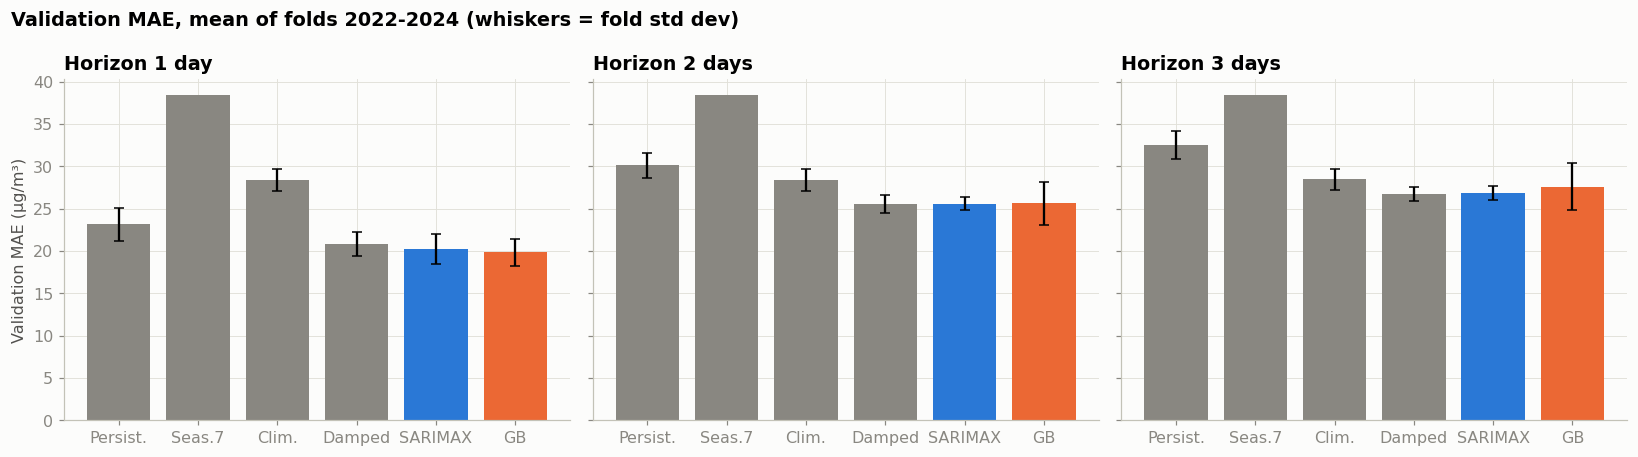

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
order = ["Persistence", "Seasonal naive (7d)", "Climatology", "Damped-anomaly persistence", "BEST_SX", "GB"]
for ax, h in zip(axes, HORIZONS):
    s = summ[summ.horizon == h].set_index("model")
    names = [BEST_SX[h] if o == "BEST_SX" else o for o in order]
    vals = [s.loc[n, "MAE_mean"] for n in names]; errs = [s.loc[n, "MAE_sd"] for n in names]
    ax.bar(range(len(names)), vals, yerr=errs, color=[MUTED] * 4 + [BLUE, ORANGE], capsize=3)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(["Persist.", "Seas.7", "Clim.", "Damped", "SARIMAX", "GB"])
    ax.set_title(f"Horizon {h} day{'s' if h > 1 else ''}"); ax.set_ylabel("Validation MAE (µg/m³)" if h == 1 else "")
fig.suptitle("Validation MAE, mean of folds 2022-2024 (whiskers = fold std dev)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "01_validation_mae")

## 8. Frozen test set (target dates 2025-01-01 → 2026-09-30)
Every model is **refitted on all training data (target ≤ 2024-12-31)** with the hyper-parameters / specification chosen in section 7, then scored once. The model marked SELECTED in section 7 is the primary result; the other rows are comparators. Nothing below feeds back into model choice.

In [13]:
def disp(name):
    return "SARIMAX (best config)" if name.startswith("SARIMAX") else name

TEST, TEST_D = {}, {}
for h, d in D.items():
    tr, te = (d.target_date <= TRAIN_END).values, (d.target_date >= TEST_START).values
    TEST_D[h] = d[te]
    bp, phi = baseline_preds(h, d, tr, TRAIN_END)
    for n in bp: TEST[(n, h)] = bp.loc[te, n].values
    cfg = BEST_SX[h].replace("SARIMAX ", "")
    F, _ = sarimax_forecasts(cfg, TRAIN_END, h if SARIMAX_CFGS[cfg]["wx"] else None)
    TEST[(BEST_SX[h], h)] = np.exp(F[h].reindex(d.index).values[te])
    for vname, cols in VAR.items():
        p, _ = gb_fit_predict(d.loc[tr, cols], d.loc[tr, "y"], d.loc[te, cols], GB_GRID[BEST_GB[h]])
        TEST[(vname, h)] = p
    assert np.isfinite(TEST[(BEST_SX[h], h)]).all() and np.isfinite(TEST[("GB", h)]).all()
print("selected per horizon:", {h: SELECTED[h] for h in HORIZONS})
print("SARIMAX config per horizon:", {h: BEST_SX[h] for h in HORIZONS})

selected per horizon: {1: 'GB', 2: 'SARIMAX ARMA(2,0,1)+F6+wx', 3: 'SARIMAX ARMA(2,0,1)+F6+wx'}
SARIMAX config per horizon: {1: 'SARIMAX ARMA(2,0,1)+F6+wx', 2: 'SARIMAX ARMA(2,0,1)+F6+wx', 3: 'SARIMAX ARMA(2,0,1)+F6+wx'}


In [14]:
MODEL_ORDER = ["Persistence", "Seasonal naive (7d)", "Climatology", "Damped-anomaly persistence",
               "SARIMAX", "GB", "GB no weather", "GB + perfect-forecast weather (ORACLE)"]
def key_for(h, label):
    return (BEST_SX[h] if label == "SARIMAX" else label, h)

rows = []; BOOT = {}
for h in HORIZONS:
    dte = TEST_D[h]
    for subset, mask in [("all test days", np.ones(len(dte), bool)), ("winter only (Nov-Jan)", (dte.is_winter_tgt == 1).values)]:
        yt = dte.y.values[mask]
        idx = block_idx(len(yt))
        entries = [(lab, TEST[key_for(h, lab)][mask]) for lab in MODEL_ORDER] + [("Always alert", np.full(mask.sum(), 1e9))]
        for lab, p in entries:
            is_sel = (lab == "SARIMAX" and SELECTED[h].startswith("SARIMAX")) or (lab == "GB" and SELECTED[h] == "GB")
            r = {"horizon": h, "subset": subset, "model": lab + (" [SELECTED]" if is_sel else ""), "n": int(mask.sum()),
                 "positives": int((yt >= THRESH).sum())}
            if lab != "Always alert": r.update(reg_metrics(yt, p))
            r.update(alert_metrics(yt, p))
            bs = boot_stats(yt, p, idx)
            for m in ["MAE", "RMSE", "precision", "recall", "F1"]:
                lo, hi = ci(bs[m]); r[f"{m}_lo"], r[f"{m}_hi"] = lo, hi
            rows.append(r); BOOT[(h, subset, lab)] = bs
test_tab = pd.DataFrame(rows)
test_tab.to_csv(OUT / "m3_test_metrics.csv", index=False)

show = ["horizon", "model", "n", "MAE", "RMSE", "precision", "recall", "F1", "TP", "FP", "FN"]
print("ALL TEST DAYS"); display(test_tab[test_tab.subset == "all test days"][show].round(2).set_index(["horizon", "model"]))

ALL TEST DAYS


n    MAE   RMSE  precision  \
horizon model                                                                  
1       Persistence                             635  18.78  30.69       0.87   
        Seasonal naive (7d)                     635  30.95  50.24       0.76   
        Climatology                             635  21.05  33.17       0.83   
        Damped-anomaly persistence              635  16.39  27.20       0.86   
        SARIMAX                                 635  15.89  25.48       0.82   
        GB [SELECTED]                           635  15.67  25.61       0.87   
        GB no weather                           635  16.74  27.66       0.86   
        GB + perfect-forecast weather (ORACLE)  635  15.66  24.71       0.86   
        Always alert                            635    NaN    NaN       0.20   
2       Persistence                             635  24.66  40.03       0.81   
        Seasonal naive (7d)                     635  30.95  50.24       0.76   
        Climatology                             635  21.05  33.17       0.83   
        Damped-anomaly persistence              635  19.79  32.01       0.86   
        SARIMAX [SELECTED]                      635  19.47  31.68       0.84   
        GB                                      635  19.27  31.20       0.84   
        GB no weather                           635  20.14  32.69       0.83   
        GB + perfect-forecast weather (ORACLE)  635  18.51  29.29       0.81   
        Always alert                            635    NaN    NaN       0.20   
3       Persistence                             635  27.54  43.54       0.79   
        Seasonal naive (7d)                     635  30.95  50.24       0.76   
        Climatology                             635  21.05  33.17       0.83   
        Damped-anomaly persistence              635  20.60  32.98       0.83   
        SARIMAX [SELECTED]                      635  19.60  32.07       0.83   
        GB                                      635  20.24  32.84       0.83   
        GB no weather                           635  21.09  34.05       0.83   
        GB + perfect-forecast weather (ORACLE)  635  19.59  30.64       0.78   
        Always alert                            635    NaN    NaN       0.20   

                                                recall    F1   TP   FP  FN  
horizon model                                                               
1       Persistence                               0.88  0.87  112   17  16  
        Seasonal naive (7d)                       0.79  0.77  101   32  27  
        Climatology                               0.92  0.87  118   24  10  
        Damped-anomaly persistence                0.92  0.89  118   20  10  
        SARIMAX                                   0.95  0.88  122   26   6  
        GB [SELECTED]                             0.92  0.89  118   18  10  
        GB no weather                             0.91  0.89  117   19  11  
        GB + perfect-forecast weather (ORACLE)    0.92  0.89  118   20  10  
        Always alert                              1.00  0.34  128  507   0  
2       Persistence                               0.82  0.82  105   24  23  
        Seasonal naive (7d)                       0.79  0.77  101   32  27  
        Climatology                               0.92  0.87  118   24  10  
        Damped-anomaly persistence                0.93  0.89  119   20   9  
        SARIMAX [SELECTED]                        0.91  0.87  117   23  11  
        GB                                        0.91  0.87  117   23  11  
        GB no weather                             0.92  0.87  118   25  10  
        GB + perfect-forecast weather (ORACLE)    0.92  0.86  118   27  10  
        Always alert                              1.00  0.34  128  507   0  
3       Persistence                               0.80  0.79  102   27  26  
        Seasonal naive (7d)                       0.79  0.77  101   32  27  
        Climatology                

In [15]:
print("WINTER ONLY (target day in Nov, Dec, Jan)")
display(test_tab[test_tab.subset != "all test days"][show].round(2).set_index(["horizon", "model"]))

WINTER ONLY (target day in Nov, Dec, Jan)


n    MAE   RMSE  precision  \
horizon model                                                                  
1       Persistence                             121  41.28  55.82       0.94   
        Seasonal naive (7d)                     121  75.93  95.22       0.86   
        Climatology                             121  49.93  62.69       0.88   
        Damped-anomaly persistence              121  36.33  50.15       0.91   
        SARIMAX                                 121  34.10  46.04       0.90   
        GB [SELECTED]                           121  34.16  46.23       0.93   
        GB no weather                           121  37.02  51.32       0.91   
        GB + perfect-forecast weather (ORACLE)  121  33.60  43.81       0.91   
        Always alert                            121    NaN    NaN       0.88   
2       Persistence                             121  58.31  74.83       0.90   
        Seasonal naive (7d)                     121  75.93  95.22       0.86   
        Climatology                             121  49.93  62.69       0.88   
        Damped-anomaly persistence              121  46.30  60.28       0.90   
        SARIMAX [SELECTED]                      121  45.90  59.62       0.88   
        GB                                      121  44.80  58.22       0.89   
        GB no weather                           121  46.81  61.47       0.88   
        GB + perfect-forecast weather (ORACLE)  121  44.25  54.97       0.88   
        Always alert                            121    NaN    NaN       0.88   
3       Persistence                             121  65.56  81.72       0.89   
        Seasonal naive (7d)                     121  75.93  95.22       0.86   
        Climatology                             121  49.93  62.69       0.88   
        Damped-anomaly persistence              121  48.83  62.39       0.88   
        SARIMAX [SELECTED]                      121  46.41  60.90       0.88   
        GB                                      121  48.47  62.41       0.88   
        GB no weather                           121  49.27  63.75       0.88   
        GB + perfect-forecast weather (ORACLE)  121  46.44  57.17       0.87   
        Always alert                            121    NaN    NaN       0.88   

                                                recall    F1   TP  FP  FN  
horizon model                                                              
1       Persistence                               0.93  0.94   99   6   7  
        Seasonal naive (7d)                       0.88  0.87   93  15  13  
        Climatology                               1.00  0.93  106  15   0  
        Damped-anomaly persistence                0.99  0.95  105  10   1  
        SARIMAX                                   0.98  0.94  104  12   2  
        GB [SELECTED]                             0.97  0.95  103   8   3  
        GB no weather                             0.98  0.95  104  10   2  
        GB + perfect-forecast weather (ORACLE)    0.97  0.94  103  10   3  
        Always alert                              1.00  0.93  106  15   0  
2       Persistence                               0.89  0.90   94  10  12  
        Seasonal naive (7d)                       0.88  0.87   93  15  13  
        Climatology                               1.00  0.93  106  15   0  
        Damped-anomaly persistence                1.00  0.95  106  12   0  
        SARIMAX [SELECTED]                        1.00  0.94  106  14   0  
        GB                                        0.99  0.94  105  13   1  
        GB no weather                             1.00  0.94  106  14   0  
        GB + perfect-forecast weather (ORACLE)    0.98  0.93  104  14   2  
        Always alert                              1.00  0.93  106  15   0  
3       Persistence                               0.88  0.89   93  11  13  
        Seasonal naive (7d)                       0.88  0.87   93  15  13  
        Climatology                               1.00  0

### 8.1 Uncertainty (95 % block-bootstrap intervals)
Intervals for the selected model and for the baselines it must beat. Paired differences use the **same resampled days** for both models, so they show whether the improvement is distinguishable from noise.

In [16]:
def fmt(m, lo, hi, nd=1): return f"{m:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"
rows = []
for h in HORIZONS:
    for subset in ["all test days", "winter only (Nov-Jan)"]:
        sub = test_tab[(test_tab.horizon == h) & (test_tab.subset == subset)]
        for lab in ["Persistence", "Damped-anomaly persistence", "SARIMAX", "GB"]:
            r = sub[sub.model.str.startswith(lab)].iloc[0]
            rows.append({"horizon": h, "subset": subset, "model": r.model, "MAE [95% CI]": fmt(r.MAE, r.MAE_lo, r.MAE_hi),
                         "RMSE [95% CI]": fmt(r.RMSE, r.RMSE_lo, r.RMSE_hi),
                         "recall [95% CI]": fmt(r.recall, r.recall_lo, r.recall_hi, 2),
                         "precision [95% CI]": fmt(r.precision, r.precision_lo, r.precision_hi, 2)})
display(pd.DataFrame(rows).set_index(["horizon", "subset", "model"]))

rows = []
for h in HORIZONS:
    sel_lab = "GB" if SELECTED[h] == "GB" else "SARIMAX"
    for subset in ["all test days", "winter only (Nov-Jan)"]:
        for ref in ["Persistence", "Damped-anomaly persistence"]:
            a, b = BOOT[(h, subset, sel_lab)], BOOT[(h, subset, ref)]
            for m in ["MAE", "F1", "recall"]:
                dlt = a[m] - b[m]; lo, hi = ci(dlt)
                rows.append({"horizon": h, "subset": subset, "selected": sel_lab, "minus": ref, "metric": m,
                             "difference [95% CI]": fmt(np.nanmean(dlt), lo, hi, 3 if m != "MAE" else 1),
                             "CI excludes 0": bool(lo > 0 or hi < 0)})
paired = pd.DataFrame(rows)
paired.to_csv(OUT / "m3_paired_differences.csv", index=False)
display(paired.set_index(["horizon", "subset", "minus", "metric"]))

MAE [95% CI]  \
horizon subset                model                                           
1       all test days         Persistence                 18.8 [15.6, 22.0]   
                              Damped-anomaly persistence  16.4 [13.7, 19.1]   
                              SARIMAX                     15.9 [13.5, 18.6]   
                              GB [SELECTED]               15.7 [13.1, 18.4]   
        winter only (Nov-Jan) Persistence                 41.3 [35.2, 48.5]   
                              Damped-anomaly persistence  36.3 [31.2, 42.5]   
                              SARIMAX                     34.1 [29.5, 40.2]   
                              GB [SELECTED]               34.2 [29.4, 40.3]   
2       all test days         Persistence                 24.7 [20.4, 29.1]   
                              Damped-anomaly persistence  19.8 [16.4, 23.4]   
                              SARIMAX [SELECTED]          19.5 [15.9, 23.2]   
                              GB                          19.3 [15.8, 22.9]   
        winter only (Nov-Jan) Persistence                 58.3 [49.3, 69.7]   
                              Damped-anomaly persistence  46.3 [39.4, 55.4]   
                              SARIMAX [SELECTED]          45.9 [37.9, 55.7]   
                              GB                          44.8 [37.3, 54.5]   
3       all test days         Persistence                 27.5 [22.6, 32.5]   
                              Damped-anomaly persistence  20.6 [16.9, 24.4]   
                              SARIMAX [SELECTED]          19.6 [16.1, 23.3]   
                              GB                          20.2 [16.3, 24.2]   
        winter only (Nov-Jan) Persistence                 65.6 [54.6, 78.6]   
                              Damped-anomaly persistence  48.8 [41.1, 58.9]   
                              SARIMAX [SELECTED]          46.4 [37.8, 56.8]   
                              GB                          48.5 [39.5, 59.5]   

                                                              RMSE [95% CI]  \
horizon subset                model                                           
1       all test days         Persistence                 30.7 [25.0, 36.0]   
                              Damped-anomaly persistence  27.2 [22.0, 31.8]   
                              SARIMAX                     25.5 [20.9, 30.0]   
                              GB [SELECTED]               25.6 [20.7, 30.1]   
        winter only (Nov-Jan) Persistence                 55.8 [47.8, 64.6]   
                              Damped-anomaly persistence  50.2 [42.6, 59.0]   
                              SARIMAX                     46.0 [38.7, 55.1]   
                              GB [SELECTED]               46.2 [38.6, 55.2]   
2       all test days         Persistence                 40.0 [32.0, 47.5]   
                              Damped-anomaly persistence  32.0 [25.7, 38.1]   
                              SARIMAX [SELECTED]          31.7 [25.1, 38.1]   
                              GB                          31.2 [24.6, 37.6]   
        winter only (Nov-Jan) Persistence                 74.8 [62.6, 89.0]   
                              Damped-anomaly persistence  60.3 [50.0, 72.7]   
                              SARIMAX [SELECTED]          59.6 [47.3, 73.2]   
                              GB                          58.2 [46.4, 72.0]   
3       all test days         Persistence                 43.5 [35.1, 51.6]   
                              Damped-anomaly persistence  33.0 [26.6, 39.4]   
                              SARIMAX [SELECTED]          32.1 [25.2, 38.9]   
                              GB                          32.8 [25.7, 39.6]   
        winter only (Nov-Jan) Persistence                 81.7 [67.4, 98.6]   
                              Damped-anomaly persistence  62.4 [51.2, 75.7]   
                              SARIMAX [SELECTED]          60.9 [48.2, 75.0]   
                              GB 

selected  \
horizon subset                minus                      metric            
1       all test days         Persistence                MAE          GB   
                                                         F1           GB   
                                                         recall       GB   
                              Damped-anomaly persistence MAE          GB   
                                                         F1           GB   
                                                         recall       GB   
        winter only (Nov-Jan) Persistence                MAE          GB   
                                                         F1           GB   
                                                         recall       GB   
                              Damped-anomaly persistence MAE          GB   
                                                         F1           GB   
                                                         recall       GB   
2       all test days         Persistence                MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   
                              Damped-anomaly persistence MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   
        winter only (Nov-Jan) Persistence                MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   
                              Damped-anomaly persistence MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   
3       all test days         Persistence                MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   
                              Damped-anomaly persistence MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   
        winter only (Nov-Jan) Persistence                MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   
                              Damped-anomaly persistence MAE     SARIMAX   
                                                         F1      SARIMAX   
                                                         recall  SARIMAX   

                                                                     difference [95% CI]  \
horizon subset                minus                      metric                            
1       all test days         Persistence                MAE           -3.1 [-4.2, -2.0]   
                                                         F1        0.024 [-0.001, 0.056]   
                                                         recall     0.049 [0.000, 0.098]   
                              Damped-anomaly persistence MAE           -0.7 [-1.4, -0.1]   
                                                         F1        0.008 [-0.021, 0.044]   
                                                         recall    0.002 [-0.046, 0.056]   
        winter only (Nov-Jan) Persistence                MAE          -7.1 [-11.5, -2.5]   
                                                         F1        0.012 [-0.009, 0.039]   
                                                         recall    0.042 [-0.009, 0.104]   
                              Damped-anomaly persistence MAE            -2.2 [-4.9, 0.7]   
                                                         F1        0.00

### 8.2 Does weather help? (interpretation ablations)
* **GB vs GB no weather** — value of *observed* (lagged) weather on top of PM2.5 history and calendar.
* **GB + ORACLE vs GB** — what a *perfect* next-days weather forecast could add. This is an upper bound only; it is not available in practice.

In [17]:
rows = []
for h in HORIZONS:
    for subset in ["all test days", "winter only (Nov-Jan)"]:
        for a_lab, b_lab in [("GB", "GB no weather"), ("GB + perfect-forecast weather (ORACLE)", "GB")]:
            a, b = BOOT[(h, subset, a_lab)], BOOT[(h, subset, b_lab)]
            for m in ["MAE", "F1"]:
                dlt = a[m] - b[m]; lo, hi = ci(dlt)
                rows.append({"horizon": h, "subset": subset, "comparison": f"{a_lab.split(' (')[0]}  minus  {b_lab}",
                             "metric": m, "difference [95% CI]": fmt(np.nanmean(dlt), lo, hi, 3 if m == "F1" else 1),
                             "CI excludes 0": bool(lo > 0 or hi < 0)})
abl2 = pd.DataFrame(rows); abl2.to_csv(OUT / "m3_weather_ablation_phase2.csv", index=False)
display(abl2.set_index(["horizon", "subset", "comparison", "metric"]))

difference [95% CI]  \
horizon subset                comparison                               metric                           
1       all test days         GB  minus  GB no weather                 MAE          -1.1 [-1.8, -0.5]   
                                                                       F1       0.009 [-0.018, 0.044]   
                              GB + perfect-forecast weather  minus  GB MAE            0.0 [-0.4, 0.4]   
                                                                       F1      -0.008 [-0.030, 0.011]   
        winter only (Nov-Jan) GB  minus  GB no weather                 MAE          -2.9 [-5.6, -0.1]   
                                                                       F1       0.007 [-0.010, 0.029]   
                              GB + perfect-forecast weather  minus  GB MAE           -0.4 [-2.0, 1.4]   
                                                                       F1      -0.010 [-0.029, 0.000]   
2       all test days         GB  minus  GB no weather                 MAE           -0.9 [-1.9, 0.1]   
                                                                       F1       0.002 [-0.020, 0.025]   
                              GB + perfect-forecast weather  minus  GB MAE           -0.7 [-1.7, 0.3]   
                                                                       F1      -0.010 [-0.042, 0.019]   
        winter only (Nov-Jan) GB  minus  GB no weather                 MAE           -2.1 [-6.3, 2.9]   
                                                                       F1       0.003 [-0.004, 0.013]   
                              GB + perfect-forecast weather  minus  GB MAE           -0.5 [-4.6, 3.6]   
                                                                       F1      -0.011 [-0.037, 0.000]   
3       all test days         GB  minus  GB no weather                 MAE           -0.9 [-1.8, 0.1]   
                                                                       F1      -0.005 [-0.033, 0.015]   
                              GB + perfect-forecast weather  minus  GB MAE           -0.6 [-1.9, 0.7]   
                                                                       F1      -0.019 [-0.053, 0.009]   
        winter only (Nov-Jan) GB  minus  GB no weather                 MAE           -0.9 [-5.7, 4.0]   
                                                                       F1        0.003 [0.000, 0.012]   
                              GB + perfect-forecast weather  minus  GB MAE           -2.0 [-7.6, 3.0]   
                                                                       F1      -0.011 [-0.037, 0.000]   

                                                                               CI excludes 0  
horizon subset                comparison                               metric                 
1       all test days         GB  minus  GB no weather                 MAE              True  
                                                                       F1              False  
                              GB + perfect-forecast weather  minus  GB MAE             False  
                                                                       F1              False  
        winter only (Nov-Jan) GB  minus  GB no weather                 MAE              True  
                                                                       F1              False  
                              GB + perfect-forecast weather  minus  GB MAE             False  
                                                                       F1              False  
2       all test days         GB  minus  GB no weather                 MAE             False  
                                                                       F1              False  
                              GB + perfect-forecast weather  minus  GB MAE             False  
                                                                       F1              False  
        winter only (

### 8.3 Alert cut-off
The alert rule so far is "forecast ≥ 120.5". Because regression forecasts shrink towards the seasonal mean, a lower cut-off may catch more events. The cut-off below is **tuned on the pooled validation folds only** (maximising F1), then applied once to the test set. Reported separately and labelled; it does not replace the 120.5 results above.

In [18]:
rows = []
for h in HORIZONS:
    key = (SELECTED[h], h)
    pv = pd.concat(VALPRED[key]); yv = D[h].loc[pv.index, "y"]
    grid = np.arange(60, 141, 2.5)
    f1s = [alert_metrics(yv.values, pv.values, g)["F1"] for g in grid]
    thr = float(grid[int(np.nanargmax(f1s))])
    dte = TEST_D[h]; p = TEST[(BEST_SX[h] if SELECTED[h].startswith("SARIMAX") else "GB", h)]
    for subset, mask in [("all test days", np.ones(len(dte), bool)), ("winter only (Nov-Jan)", (dte.is_winter_tgt == 1).values)]:
        a120 = alert_metrics(dte.y.values[mask], p[mask], THRESH); at = alert_metrics(dte.y.values[mask], p[mask], thr)
        rows.append({"horizon": h, "subset": subset, "val-tuned cut-off": thr,
                     "F1 @120.5": a120["F1"], "recall @120.5": a120["recall"], "precision @120.5": a120["precision"],
                     "F1 @tuned": at["F1"], "recall @tuned": at["recall"], "precision @tuned": at["precision"]})
cutoff_tab = pd.DataFrame(rows); cutoff_tab.to_csv(OUT / "m3_alert_cutoff.csv", index=False)
display(cutoff_tab.round(3).set_index(["horizon", "subset"]))

val-tuned cut-off  F1 @120.5  recall @120.5  \
horizon subset                                                               
1       all test days                      120.0      0.894          0.922   
        winter only (Nov-Jan)              120.0      0.949          0.972   
2       all test days                      122.5      0.873          0.914   
        winter only (Nov-Jan)              122.5      0.938          1.000   
3       all test days                      122.5      0.869          0.906   
        winter only (Nov-Jan)              122.5      0.934          1.000   

                               precision @120.5  F1 @tuned  recall @tuned  \
horizon subset                                                              
1       all test days                     0.868      0.891          0.922   
        winter only (Nov-Jan)             0.928      0.949          0.972   
2       all test days                     0.836      0.871          0.898   
        winter only (Nov-Jan)             0.883      0.937          0.991   
3       all test days                     0.835      0.864          0.891   
        winter only (Nov-Jan)             0.876      0.929          0.991   

                               precision @tuned  
horizon subset                                   
1       all test days                     0.861  
        winter only (Nov-Jan)             0.928  
2       all test days                     0.846  
        winter only (Nov-Jan)             0.890  
3       all test days                     0.838  
        winter only (Nov-Jan)             0.875

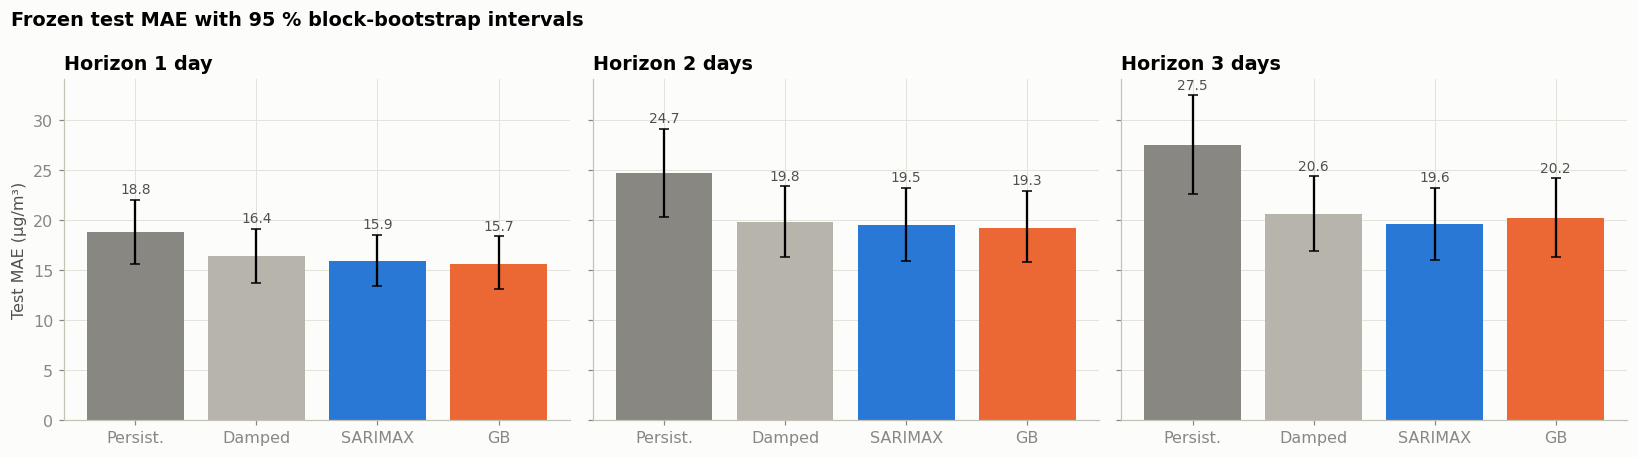

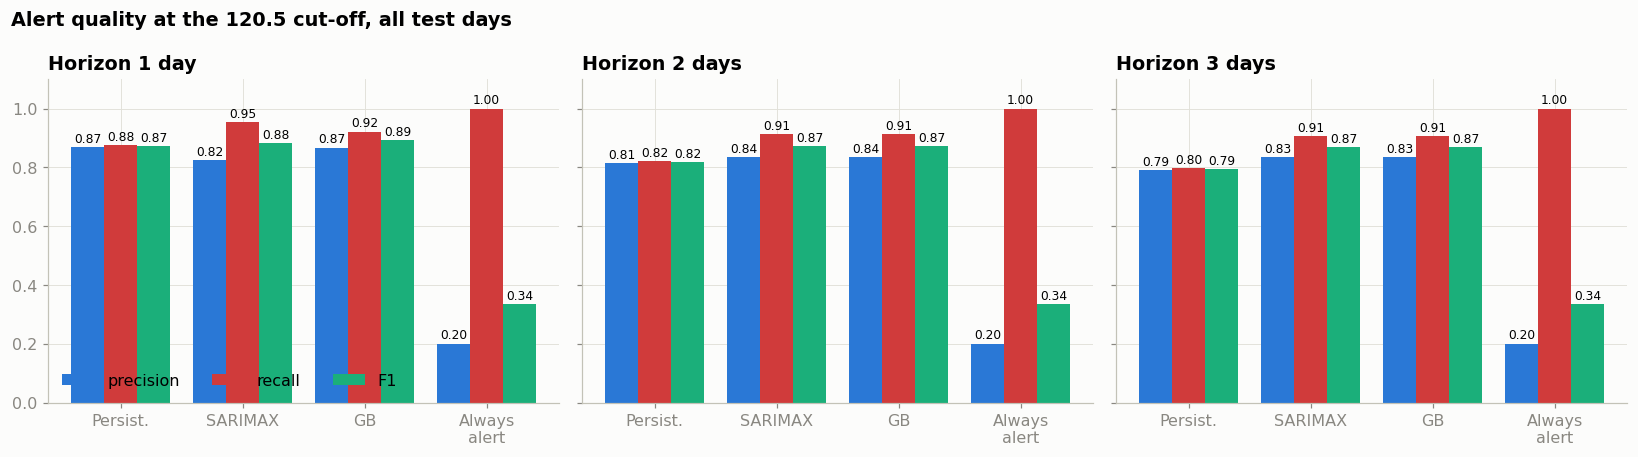

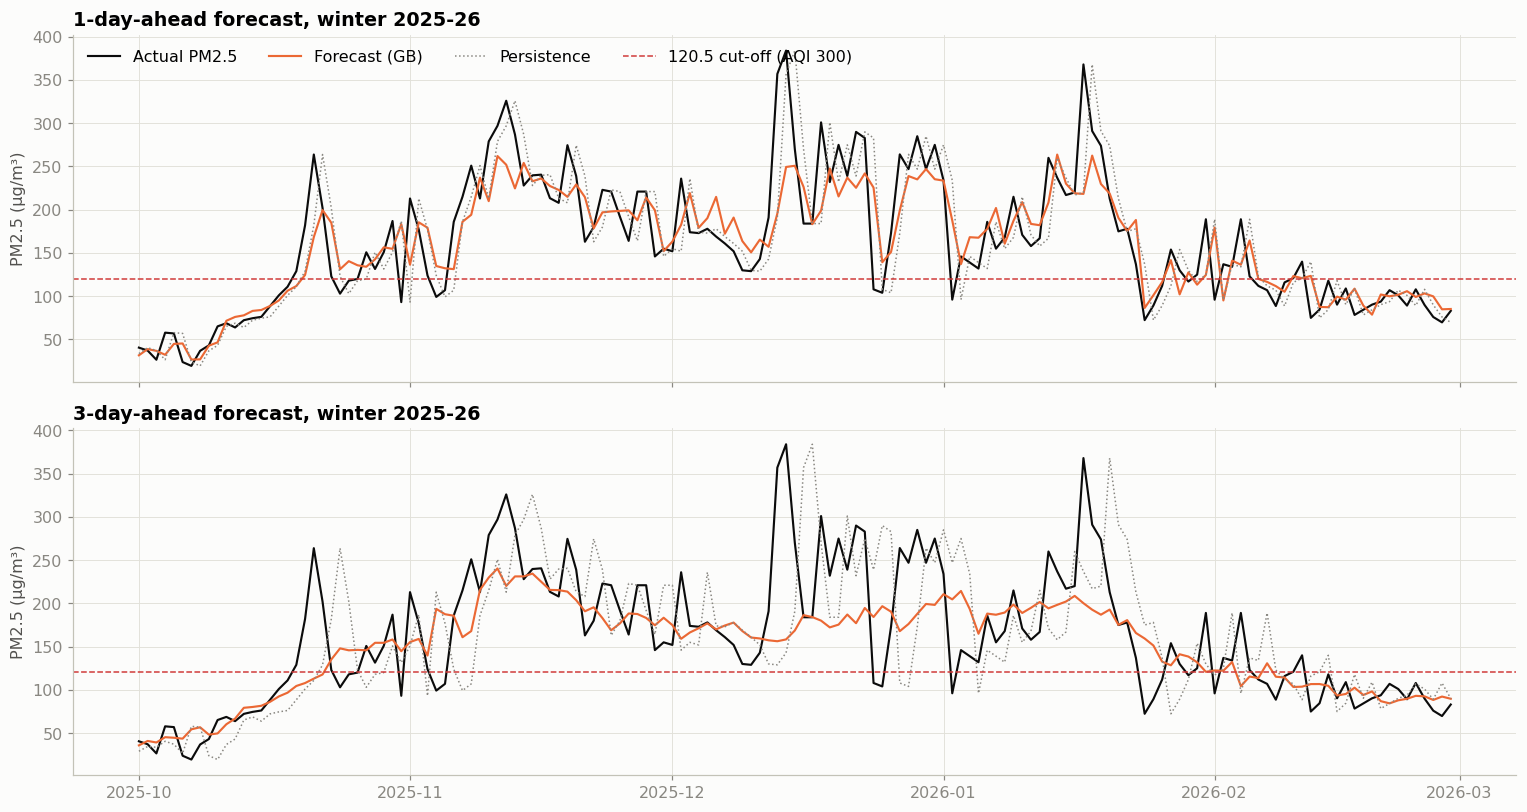

In [19]:
# ---------- test-set figures ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
labs = ["Persistence", "Damped-anomaly persistence", "SARIMAX", "GB"]; cols = [MUTED, "#b7b5ab", BLUE, ORANGE]
for ax, h in zip(axes, HORIZONS):
    sub = test_tab[(test_tab.horizon == h) & (test_tab.subset == "all test days")]
    for i, (lab, c) in enumerate(zip(labs, cols)):
        r = sub[sub.model.str.startswith(lab)].iloc[0]
        ax.bar(i, r.MAE, color=c, yerr=[[r.MAE - r.MAE_lo], [r.MAE_hi - r.MAE]], capsize=3)
        ax.text(i, r.MAE_hi + 0.6, f"{r.MAE:.1f}", ha="center", fontsize=9, color=INK2)
    ax.set_xticks(range(4)); ax.set_xticklabels(["Persist.", "Damped", "SARIMAX", "GB"])
    ax.set_title(f"Horizon {h} day{'s' if h > 1 else ''}"); ax.set_ylabel("Test MAE (µg/m³)" if h == 1 else "")
fig.suptitle("Frozen test MAE with 95 % block-bootstrap intervals", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "02_test_mae")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, h in zip(axes, HORIZONS):
    sub = test_tab[(test_tab.horizon == h) & (test_tab.subset == "all test days")]
    labs2 = ["Persistence", "SARIMAX", "GB", "Always alert"]
    x = np.arange(len(labs2)); w = 0.27
    for j, (m, c) in enumerate([("precision", BLUE), ("recall", RED), ("F1", AQUA)]):
        vals = [sub[sub.model.str.startswith(l)].iloc[0][m] for l in labs2]
        b = ax.bar(x + (j - 1) * w, vals, w, color=c, label=m); ax.bar_label(b, fmt="%.2f", fontsize=8, padding=1)
    ax.set_xticks(x); ax.set_xticklabels(["Persist.", "SARIMAX", "GB", "Always\nalert"]); ax.set_ylim(0, 1.1)
    ax.set_title(f"Horizon {h} day{'s' if h > 1 else ''}")
axes[0].legend(ncol=3, loc="lower left")
fig.suptitle("Alert quality at the 120.5 cut-off, all test days", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_test_alert_quality")

fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)
for ax, h in zip(axes, [1, 3]):
    dte = TEST_D[h]; sel_key = (BEST_SX[h] if SELECTED[h].startswith("SARIMAX") else "GB", h)
    win = ((dte.target_date >= "2025-10-01") & (dte.target_date <= "2026-02-28")).values
    t = dte.target_date[win]
    ax.plot(t, dte.y[win], color=INK, lw=1.4, label="Actual PM2.5")
    ax.plot(t, TEST[sel_key][win], color=ORANGE, lw=1.4, label=f"Forecast ({disp(SELECTED[h])})")
    ax.plot(t, TEST[("Persistence", h)][win], color=MUTED, lw=1, ls=":", label="Persistence")
    ax.axhline(THRESH, color=RED, lw=1, ls="--", label="120.5 cut-off (AQI 300)")
    ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title(f"{h}-day-ahead forecast, winter 2025-26")
axes[0].legend(ncol=4, loc="upper left"); fig.tight_layout(); save(fig, "04_winter_forecasts")

### 8.4 What drives the gradient-boosting forecast?
Group permutation importance on **validation fold 2024** (model fitted on target dates before 2024): how much MAE rises when a feature group is shuffled across rows. This uses validation, not test data.

In [20]:
GROUPS = {"PM2.5 history (lags, means)": AR_COLS, "Weather at origin day": WX_COLS, "Target-day calendar": CAL_TGT}
rows = []
rng = np.random.default_rng(SEED)
for h in HORIZONS:
    d = D[h]; tr, va = fold_masks(d, 2024)
    _, m = gb_fit_predict(d.loc[tr, GB_COLS], d.loc[tr, "y"], d.loc[va, GB_COLS], GB_GRID[BEST_GB[h]])
    Xv, yv = d.loc[va, GB_COLS].copy(), d.loc[va, "y"].values
    base = reg_metrics(yv, np.exp(m.predict(Xv)))["MAE"]
    for g, cols in GROUPS.items():
        inc = []
        for _ in range(10):
            Xp = Xv.copy(); perm = rng.permutation(len(Xp)); Xp[cols] = Xv[cols].values[perm]
            inc.append(reg_metrics(yv, np.exp(m.predict(Xp)))["MAE"] - base)
        rows.append({"horizon": h, "group": g, "MAE increase when shuffled": np.mean(inc)})
imp = pd.DataFrame(rows); imp.to_csv(OUT / "m3_gb_group_importance.csv", index=False)
display(imp.pivot(index="group", columns="horizon", values="MAE increase when shuffled").round(2))

horizon,1,2,3
group,,,
"PM2.5 history (lags, means)",38.05,20.84,15.37
Target-day calendar,2.36,8.70,12.56
Weather at origin day,8.39,6.95,4.38


# Part II — Phase 1 checks
Phase 1 reported a high-risk classifier that narrowly beats persistence (F1 0.877 vs 0.867 on the test set, models statistically tied in CV). Before Phase 2 is compared with it, three things decide whether the Phase 1 comparison can be trusted:

1. **Rolling / lagged features must only use past days** (no window that includes the day being predicted).
2. **No single feature should predict the label almost perfectly** (a near-1.0 single-feature AUC means the label leaked in).
3. **How much of Phase 1's skill rests on same-day weather**, which at forecast time would have to be a *forecast* (a perfect one, in the Phase 1 setup).

The notebook rebuilds the Phase 1 feature set from `m4_full_engineered.csv`: if `m4_feature_list.csv` (Phase 1's own list) is placed next to this notebook it is used, otherwise the list is reconstructed using the M5 rules (all numeric engineered columns, minus raw / same-day pollution columns, minus the target and its relatives). Re-run with the real list to confirm the numbers.

In [21]:
BANNED = ["high_risk", "high_risk_city", "pm25_target", "pm25_ref_station", "target_source", "aqi_pm25", "aqi_category",
          "next_pm25", "pm25_mean", "pm25_median", "pm25_n_stations", "pm25_n_extreme_flagged",
          "pm10_mean", "pm10_median", "pm10_n_stations", "pm10_n_extreme_flagged",
          "pm25_mean_change", "pm25_pm10_ratio", "pm10_available"]
def assert_no_banned(features):
    # Ban-list: same-day or future information about the target day must never be a model input.
    bad = sorted(set(features) & set(BANNED))
    assert not bad, f"banned columns in feature list: {bad}"
    return True

NON_NUMERIC = ["target_source", "aqi_category", "season"]
P1_EXTRA_DROP = ["prev_pm25", "year"]          # prev_pm25 dropped in the final target code; year = drift feature
list_file = DATA / "m4_feature_list.csv"
if list_file.exists():
    P1_FEATURES = pd.read_csv(list_file)["feature"].tolist(); src = "m4_feature_list.csv (Phase 1's own list)"
else:
    P1_FEATURES = [c for c in m4.columns if c not in BANNED + NON_NUMERIC + P1_EXTRA_DROP and pd.api.types.is_numeric_dtype(m4[c])]
    src = "RECONSTRUCTED (m4_feature_list.csv not found)"
assert_no_banned(P1_FEATURES)
print(f"Phase 1 feature list: {len(P1_FEATURES)} features, source = {src}")
print("ban-list assertion passed: no banned column is a model input")
print("\nColumns present in m4_full_engineered.csv that MUST stay out of any model:")
print([c for c in BANNED if c in m4.columns])

Phase 1 feature list: 95 features, source = RECONSTRUCTED (m4_feature_list.csv not found)
ban-list assertion passed: no banned column is a model input

Columns present in m4_full_engineered.csv that MUST stay out of any model:
['high_risk', 'high_risk_city', 'pm25_target', 'pm25_ref_station', 'target_source', 'aqi_pm25', 'aqi_category', 'next_pm25', 'pm25_mean', 'pm25_median', 'pm25_n_stations', 'pm25_n_extreme_flagged', 'pm10_mean', 'pm10_median', 'pm10_n_stations', 'pm10_n_extreme_flagged', 'pm25_mean_change', 'pm25_pm10_ratio', 'pm10_available']


## 9. Check 1 — rolling and lagged features: past only?
Every engineered column is rebuilt from the raw column two ways: **past-only** (`shift(1)` before the window) and **window includes day *t***. A safe column matches the first and not the second.

In [22]:
def match(a, b, atol=1e-8):
    ok = a.notna() & b.notna()
    return float(np.isclose(a[ok], b[ok], atol=atol, rtol=1e-6).mean()) if ok.sum() else np.nan, int(ok.sum())

def disc(col, past, incl, atol=1e-8):
    # compare the column with the past-only and the includes-day-t rebuild ONLY on rows where those two differ,
    # otherwise persistent / zero-heavy series (rain, binary labels) would match both by accident
    ok = col.notna() & past.notna() & incl.notna() & ((past - incl).abs() > max(atol, 1e-6))
    if ok.sum() < 20: return np.nan, np.nan, int(ok.sum())
    return (float(np.isclose(col[ok], past[ok], atol=atol, rtol=1e-6).mean()),
            float(np.isclose(col[ok], incl[ok], atol=atol, rtol=1e-6).mean()), int(ok.sum()))

hr = m4["high_risk"]
def aqi_pm25(c):
    bp = [(0, 30, 0, 50), (31, 60, 51, 100), (61, 90, 101, 200), (91, 120, 201, 300), (121, 250, 301, 400), (251, 380, 401, 500)]
    if pd.isna(c): return np.nan
    c = int(c + 0.5)
    for lo, hi, a, b in bp:
        if c <= hi: return (b - a) / (hi - lo) * (c - lo) + a
    return 500.0
aqi_ref = m4["pm25_ref_station"].map(aqi_pm25)

rows = []
def add(col, rule, past, incl, atol=1e-8):
    if col.endswith("_std"): atol = max(atol, 1e-3)      # rolling std of constant windows carries float noise that differs between pandas versions
    mp, n = match(m4[col], past, atol); dp, di, nd = disc(m4[col], past, incl, atol)
    rows.append({"feature": col, "rule": rule, "matches past-only (all rows)": mp, "rows": n,
                 "rows where past/incl differ": nd, "matches past-only (those rows)": dp, "matches incl. day t (those rows)": di})
for base in ["pm25_mean", "temp_mean", "humidity_mean", "wind_speed_mean", "pressure_mean", "precip_sum"]:
    for w in (3, 7):
        for stat in ("mean", "std"):
            col = f"{base}_roll{w}_{stat}"
            if col not in m4: continue
            past = getattr(m4[base].shift(1).rolling(w, min_periods=1), stat)()
            incl = getattr(m4[base].rolling(w, min_periods=1), stat)()
            add(col, f"{stat} of {base} over previous {w} days", past, incl)
    for k in (1, 2, 3):
        col = f"{base}_lag{k}"
        if col in m4: add(col, f"{base} shifted by {k}", m4[base].shift(k), m4[base].shift(k - 1))
for k in (1, 2, 3):
    add(f"aqi_pm25_lag{k}", f"PM-only AQI of reference-station PM2.5 shifted by {k} (±3 AQI points)", aqi_ref.shift(k), aqi_ref.shift(k - 1), atol=3.0)
add("prev_high_risk", "high_risk shifted by 1", hr.shift(1), hr)
for w in (3, 7):
    add(f"high_risk_past{w}d", f"sum of high_risk over previous {w} days", hr.shift(1).rolling(w, min_periods=1).sum(), hr.rolling(w, min_periods=1).sum())
leak = pd.DataFrame(rows)
leak["verdict"] = np.where((leak["matches past-only (all rows)"] > 0.98) &
                           ((leak["matches past-only (those rows)"] > 0.95) | leak["matches past-only (those rows)"].isna()) &
                           ((leak["matches incl. day t (those rows)"] < 0.1) | leak["matches incl. day t (those rows)"].isna()),
                           "past-only OK", "CHECK")
leak.to_csv(OUT / "m3_phase1_rolling_leakage_check.csv", index=False)
print(f"{(leak.verdict == 'past-only OK').sum()} of {len(leak)} engineered columns verified past-only; flagged: {leak.loc[leak.verdict == 'CHECK', 'feature'].tolist()}")
display(leak.round(3).set_index("feature"))

48 of 48 engineered columns verified past-only; flagged: []


,rule,matches past-only (all rows),rows,rows where past/incl differ,matches past-only (those rows),matches incl. day t (those rows),verdict
feature,,,,,,,
pm25_mean_roll3_mean,mean of pm25_mean over previous 3 days,1.0,3093,3049,1.0,0.000,past-only OK
pm25_mean_roll3_std,std of pm25_mean over previous 3 days,1.0,3021,2962,1.0,0.000,past-only OK
pm25_mean_roll7_mean,mean of pm25_mean over previous 7 days,1.0,3133,3086,1.0,0.000,past-only OK
pm25_mean_roll7_std,std of pm25_mean over previous 7 days,1.0,3119,3068,1.0,0.000,past-only OK
pm25_mean_lag1,pm25_mean shifted by 1,1.0,2933,2800,1.0,0.000,past-only OK
pm25_mean_lag2,pm25_mean shifted by 2,1.0,2932,2800,1.0,0.000,past-only OK
pm25_mean_lag3,pm25_mean shifted by 3,1.0,2931,2799,1.0,0.000,past-only OK
temp_mean_roll3_mean,mean of temp_mean over previous 3 days,1.0,3194,3193,1.0,0.000,past-only OK
temp_mean_roll3_std,std of temp_mean over previous 3 days,1.0,3193,3182,1.0,0.000,past-only OK


In [23]:
# same-day columns that sit in the file but are NOT past-only: show how much they know about the label
same_day = {"aqi_pm25 (> 300 <=> high_risk?)": ((m4["aqi_pm25"] > 300).astype(float)[m4.high_risk.notna() & m4.aqi_pm25.notna()]
                                                == m4.loc[m4.high_risk.notna() & m4.aqi_pm25.notna(), "high_risk"]).mean(),
            "PM-only AQI of same-day reference value, within ±3 points": match(m4["aqi_pm25"], aqi_ref, atol=3.0)[0],
            "corr(pm25_mean, pm25_target) same day": m4[["pm25_mean", "pm25_target"]].corr().iloc[0, 1],
            "next_pm25 == pm25_mean shifted by -1 (tomorrow's value)": match(m4["next_pm25"], m4["pm25_mean"].shift(-1))[0]}
print("Columns that are in the file but are leaks if used as inputs:")
for k, v in same_day.items(): print(f"  {k}: {v:.3f}")

Columns that are in the file but are leaks if used as inputs:
  aqi_pm25 (> 300 <=> high_risk?): 1.000
  PM-only AQI of same-day reference value, within ±3 points: 1.000
  corr(pm25_mean, pm25_target) same day: 0.985
  next_pm25 == pm25_mean shifted by -1 (tomorrow's value): 1.000


## 10. Check 2 — single-feature AUC
For each candidate feature the AUC of that feature alone against `high_risk` (training rows only; folded as max(AUC, 1−AUC) so direction does not matter). A legitimate lag feature can be strong (yesterday predicts today) but should stay clearly below ~0.95; the banned columns are included for contrast and should light up.

Phase 1 features with single-feature AUC >= 0.99 (label leak): []
Strong features, 0.95 <= AUC < 0.99: ['aqi_pm25_lag1', 'pm25_mean_lag1', 'pm25_mean_roll3_mean', 'pm25_mean_roll7_mean']
  of these, verified past-only in Check 1: ['aqi_pm25_lag1', 'pm25_mean_lag1', 'pm25_mean_roll3_mean', 'pm25_mean_roll7_mean'] | NOT verified: []

Top 15 Phase 1 features (train rows):


,AUC (folded)
aqi_pm25_lag1,0.971
pm25_mean_lag1,0.965
pm25_mean_roll3_mean,0.957
pm25_mean_roll7_mean,0.952
aqi_pm25_lag2,0.950
pm25_mean_lag2,0.943
high_risk_past7d,0.943
aqi_pm25_lag3,0.935
day_of_year_cos,0.934
high_risk_past3d,0.931


Banned columns for contrast:


,AUC (folded)
pm25_target,1.000
pm25_ref_station,1.000
aqi_pm25,1.000
pm25_median,0.993
pm25_mean,0.993
high_risk_city,0.972
next_pm25,0.963
pm10_mean,0.917
pm10_median,0.917
pm25_pm10_ratio,0.896


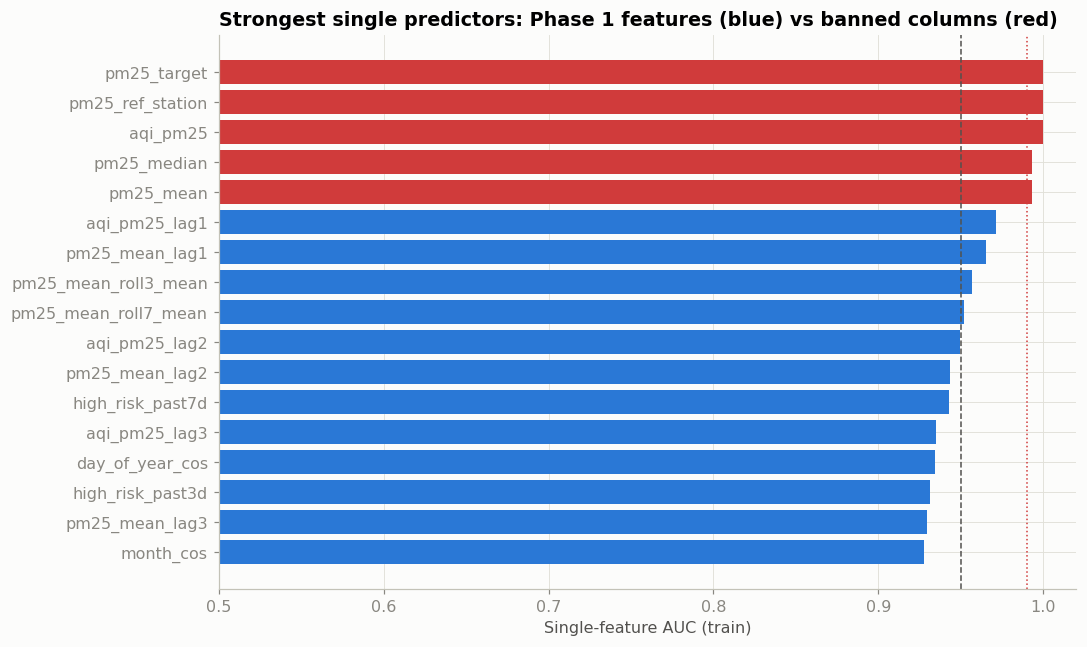

In [24]:
lab = m4["high_risk"]
tr_mask = (m4.index <= TRAIN_END) & lab.notna().values
def sf_auc(col, mask=tr_mask):
    x = m4.loc[mask, col]; ok = x.notna()
    if ok.sum() < 100 or lab[mask][ok].nunique() < 2: return np.nan
    a = roc_auc_score(lab[mask][ok], x[ok]); return max(a, 1 - a)
auc_p1 = pd.Series({c: sf_auc(c) for c in P1_FEATURES}).dropna().sort_values(ascending=False)
ban_num = [c for c in BANNED if c in m4.columns and pd.api.types.is_numeric_dtype(m4[c]) and c not in ("high_risk",)]
auc_ban = pd.Series({c: sf_auc(c) for c in ban_num}).dropna().sort_values(ascending=False)
FLAG, LEAK = 0.95, 0.99
print(f"Phase 1 features with single-feature AUC >= {LEAK} (label leak): {auc_p1[auc_p1 >= LEAK].index.tolist()}")
strong = auc_p1[(auc_p1 >= FLAG) & (auc_p1 < LEAK)].index.tolist()
ok_names = set(leak.loc[leak.verdict == "past-only OK", "feature"])
print(f"Strong features, {FLAG} <= AUC < {LEAK}: {strong}")
print("  of these, verified past-only in Check 1:", [c for c in strong if c in ok_names], "| NOT verified:", [c for c in strong if c not in ok_names])
print("\nTop 15 Phase 1 features (train rows):"); display(auc_p1.head(15).round(3).to_frame("AUC (folded)"))
print("Banned columns for contrast:"); display(auc_ban.round(3).to_frame("AUC (folded)"))
pd.concat([auc_p1.rename("AUC").to_frame().assign(group="Phase 1 feature"), auc_ban.rename("AUC").to_frame().assign(group="banned")]).to_csv(OUT / "m3_phase1_single_feature_auc.csv")

fig, ax = plt.subplots(figsize=(10, 6))
top = auc_p1.head(12)[::-1]; allv = pd.concat([top, auc_ban.head(5)[::-1]])
colors = [BLUE] * len(top) + [RED] * len(auc_ban.head(5))
ax.barh(range(len(allv)), allv.values, color=colors); ax.set_yticks(range(len(allv))); ax.set_yticklabels(allv.index)
ax.axvline(FLAG, color=INK2, ls="--", lw=1); ax.axvline(LEAK, color=RED, ls=":", lw=1); ax.set_xlim(0.5, 1.02); ax.set_xlabel("Single-feature AUC (train)")
ax.set_title("Strongest single predictors: Phase 1 features (blue) vs banned columns (red)")
fig.tight_layout(); save(fig, "05_single_feature_auc")

## 11. Check 3 — same-day weather ablation (Phase 1 classifier)
Phase 1 predicted the high-risk label of day *t* using the weather of day *t* (a perfect forecast). Re-run the Phase 1 style classifier (balanced gradient-boosting classifier, 0.5 probability cut-off, identical settings for all variants) with:

* **A. Full Phase 1 features** (same-day weather included)
* **B. Without same-day weather** (lagged and rolling weather kept)
* **C. Without any weather** (pollution history + calendar + Diwali only)
* **Persistence** (yesterday's label)

Same train/test split as Phase 1 (train ≤ 2024, test ≥ 2025, rows with an observed label).

In [25]:
SAME_DAY_WX = (["temp_mean", "temp_min", "temp_max", "humidity_mean", "dewpoint_mean", "wind_speed_mean", "wind_gust_max",
                "pressure_mean", "precip_sum", "cloud_mean", "wind_dir_deg", "temp_range", "wind_humidity_interaction",
                "temp_pressure_interaction", "low_wind", "is_dry_day", "high_humidity", "is_cold_day", "cold_calm_dry",
                "temp_mean_change", "humidity_mean_change", "wind_speed_mean_change", "pressure_mean_change"])
WX_KEYS = ("temp_", "humidity_", "wind_", "pressure_", "precip_", "cloud_", "dewpoint_", "is_dry", "low_wind", "high_humidity", "is_cold", "cold_calm")
SD = [c for c in P1_FEATURES if c in SAME_DAY_WX]
ALLWX = [c for c in P1_FEATURES if c in SD or (c.startswith(WX_KEYS) and c not in ("is_weekend",))]
F_A = P1_FEATURES
F_B = [c for c in P1_FEATURES if c not in SD]
F_C = [c for c in P1_FEATURES if c not in ALLWX]
print(f"A: {len(F_A)} features | B (no same-day weather): {len(F_B)} | C (no weather at all): {len(F_C)}")
print("same-day weather columns removed in B:", SD)

p1 = m4[lab.notna()].copy(); p1["pm25"] = y.reindex(p1.index)
p1_tr, p1_te = p1[p1.index <= TRAIN_END], p1[p1.index >= TEST_START]
CLF = dict(class_weight="balanced", learning_rate=0.05, max_depth=3, max_iter=200, random_state=SEED)
def fit_clf(cols):
    m = HistGradientBoostingClassifier(**CLF).fit(p1_tr[cols], p1_tr["high_risk"].astype(int))
    pr = m.predict_proba(p1_te[cols])[:, 1]; return pr, (pr >= 0.5).astype(int)
P1_PRED = {}
for name, cols in [("A. Full Phase 1 features", F_A), ("B. No same-day weather", F_B), ("C. No weather at all", F_C)]:
    pr, pc = fit_clf(cols); P1_PRED[name] = (pr, pc)
P1_PRED["Persistence (yesterday's label)"] = (None, p1_te["prev_high_risk"].fillna(0).astype(int).values)

def clf_table(subset_mask, label):
    yt = p1_te["pm25"].values[subset_mask]; idx = block_idx(len(yt)); rows = []
    for name, (pr, pc) in P1_PRED.items():
        yp = np.where(pc[subset_mask] == 1, 1000.0, 0.0)
        r = {"subset": label, "model": name, **alert_metrics(yt, yp)}
        bs = boot_stats(yt, yp, idx)
        for m in ["precision", "recall", "F1"]: r[f"{m}_lo"], r[f"{m}_hi"] = ci(bs[m])
        r["ROC-AUC"] = roc_auc_score(p1_te["high_risk"].values[subset_mask], pr[subset_mask]) if pr is not None else np.nan
        rows.append(r)
    return pd.DataFrame(rows)
winter_p1 = p1_te.index.month.isin([11, 12, 1])
abl = pd.concat([clf_table(np.ones(len(p1_te), bool), "all test days"), clf_table(winter_p1, "winter only (Nov-Jan)")])
abl.to_csv(OUT / "m3_phase1_ablation.csv", index=False)
print(f"test rows: {len(p1_te)}, high-risk: {int(p1_te.high_risk.sum())}; winter rows: {int(winter_p1.sum())}")
display(abl[["subset", "model", "precision", "recall", "F1", "F1_lo", "F1_hi", "ROC-AUC", "TP", "FP", "FN"]].round(3).set_index(["subset", "model"]))

A: 95 features | B (no same-day weather): 72 | C (no weather at all): 34
same-day weather columns removed in B: ['temp_mean', 'temp_min', 'temp_max', 'humidity_mean', 'dewpoint_mean', 'wind_speed_mean', 'wind_gust_max', 'pressure_mean', 'precip_sum', 'cloud_mean', 'wind_dir_deg', 'temp_mean_change', 'humidity_mean_change', 'wind_speed_mean_change', 'pressure_mean_change', 'temp_range', 'wind_humidity_interaction', 'temp_pressure_interaction', 'low_wind', 'is_dry_day', 'high_humidity', 'is_cold_day', 'cold_calm_dry']
test rows: 635, high-risk: 128; winter rows: 121


precision  recall  \
subset                model                                                
all test days         A. Full Phase 1 features             0.801   0.945   
                      B. No same-day weather               0.797   0.953   
                      C. No weather at all                 0.776   0.945   
                      Persistence (yesterday's label)      0.867   0.867   
winter only (Nov-Jan) A. Full Phase 1 features             0.912   0.981   
                      B. No same-day weather               0.929   0.991   
                      C. No weather at all                 0.897   0.991   
                      Persistence (yesterday's label)      0.942   0.925   

                                                          F1  F1_lo  F1_hi  \
subset                model                                                  
all test days         A. Full Phase 1 features         0.867  0.797  0.917   
                      B. No same-day weather           0.868  0.794  0.920   
                      C. No weather at all             0.852  0.770  0.910   
                      Persistence (yesterday's label)  0.867  0.789  0.919   
winter only (Nov-Jan) A. Full Phase 1 features         0.945  0.901  0.983   
                      B. No same-day weather           0.959  0.921  0.987   
                      C. No weather at all             0.942  0.890  0.979   
                      Persistence (yesterday's label)  0.933  0.893  0.974   

                                                       ROC-AUC   TP  FP  FN  
subset                model                                                  
all test days         A. Full Phase 1 features           0.985  121  30   7  
                      B. No same-day weather             0.983  122  31   6  
                      C. No weather at all               0.983  121  35   7  
                      Persistence (yesterday's label)      NaN  111  17  17  
winter only (Nov-Jan) A. Full Phase 1 features           0.947  104  10   2  
                      B. No same-day weather             0.908  105   8   1  
                      C. No weather at all               0.835  105  12   1  
                      Persistence (yesterday's label)      NaN   98   6   8

,F1 difference [95% CI],CI excludes 0
comparison,,
A minus B (value of same-day weather),"-0.001 [-0.023, 0.024]",False
A minus C (value of all weather),"0.016 [-0.014, 0.048]",False
A minus persistence (Phase 1 headline),"-0.000 [-0.036, 0.031]",False
B minus persistence,"0.001 [-0.046, 0.040]",False


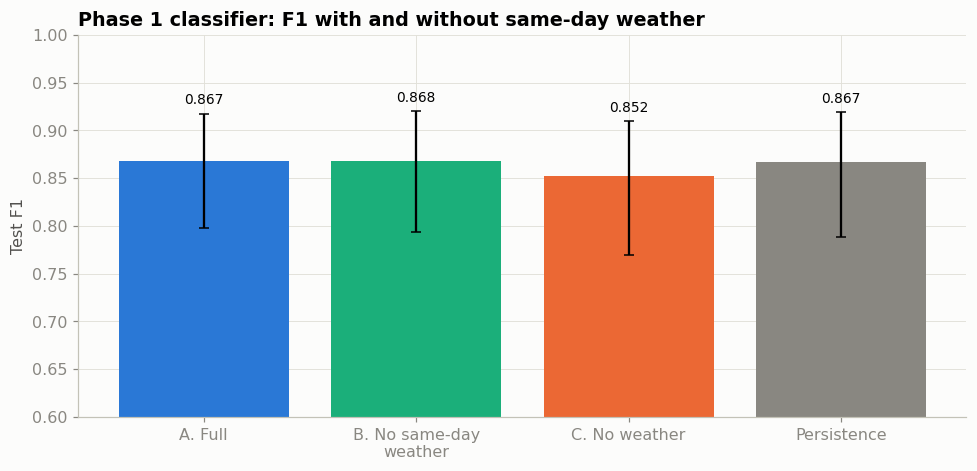

In [26]:
# paired bootstrap: does removing same-day weather change F1? does Phase 1 beat persistence?
yt = p1_te["pm25"].values; idx = block_idx(len(yt)); rows = []
def bs_of(name): return boot_stats(yt, np.where(P1_PRED[name][1] == 1, 1000.0, 0.0), idx)
A, B, Cc, Pp = (bs_of(k) for k in ["A. Full Phase 1 features", "B. No same-day weather", "C. No weather at all", "Persistence (yesterday's label)"])
for lab_, x, z in [("A minus B (value of same-day weather)", A, B), ("A minus C (value of all weather)", A, Cc),
                   ("A minus persistence (Phase 1 headline)", A, Pp), ("B minus persistence", B, Pp)]:
    d_ = x["F1"] - z["F1"]; lo, hi = ci(d_)
    rows.append({"comparison": lab_, "F1 difference [95% CI]": fmt(np.nanmean(d_), lo, hi, 3), "CI excludes 0": bool(lo > 0 or hi < 0)})
phase1_paired = pd.DataFrame(rows); phase1_paired.to_csv(OUT / "m3_phase1_ablation_paired.csv", index=False)
display(phase1_paired.set_index("comparison"))

fig, ax = plt.subplots(figsize=(9, 4.4))
sub = abl[abl.subset == "all test days"]
for i, (_, r) in enumerate(sub.iterrows()):
    ax.bar(i, r.F1, color=[BLUE, AQUA, ORANGE, MUTED][i], yerr=[[r.F1 - r.F1_lo], [r.F1_hi - r.F1]], capsize=3)
    ax.text(i, r.F1_hi + 0.01, f"{r.F1:.3f}", ha="center", fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(["A. Full", "B. No same-day\nweather", "C. No weather", "Persistence"]); ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Test F1"); ax.set_title("Phase 1 classifier: F1 with and without same-day weather")
fig.tight_layout(); save(fig, "06_phase1_ablation")

## 12. Phase 2 vs Phase 1 on the same rows
Phase 1 predicts the label of day *t* with day-*t* weather. The closest Phase 2 setting is **horizon 1** (forecast day *t+1* from information up to day *t*, no same-day weather). Here both are scored on the **same test days** and the same 0/1 alert target. Phase 2's alert is "forecast PM2.5 ≥ 120.5".

In [27]:
h = 1; dte = TEST_D[h]
cmp_idx = dte.target_date.values                     # target day for each Phase 2 row
common = [dt for dt in cmp_idx if dt in p1_te.index]
sel_key = (BEST_SX[1] if SELECTED[1].startswith("SARIMAX") else "GB", 1)
sel_pred = pd.Series(TEST[sel_key], index=pd.DatetimeIndex(cmp_idx)).loc[common]
pers_pred = pd.Series(TEST[("Persistence", 1)], index=pd.DatetimeIndex(cmp_idx)).loc[common]
ytc = p1_te.loc[common, "pm25"].values
rows = []
cands = {"Phase 1 persistence (label)": np.where(p1_te.loc[common, "prev_high_risk"].fillna(0).values == 1, 1000., 0.),
         "Phase 1 full classifier (A, same-day weather)": np.where(pd.Series(P1_PRED["A. Full Phase 1 features"][1], index=p1_te.index).loc[common].values == 1, 1000., 0.),
         "Phase 1 classifier without same-day weather (B)": np.where(pd.Series(P1_PRED["B. No same-day weather"][1], index=p1_te.index).loc[common].values == 1, 1000., 0.),
         "Phase 2 persistence (PM2.5 >= 120.5)": pers_pred.values,
         "Climatology only (seasonal curve, no recent data)": pd.Series(TEST[("Climatology", 1)], index=pd.DatetimeIndex(cmp_idx)).loc[common].values,
         f"Phase 2 selected: {disp(SELECTED[1])}": sel_pred.values}
idx = block_idx(len(ytc))
for k, v in cands.items():
    r = {"model": k, **alert_metrics(ytc, v)}; bs = boot_stats(ytc, v, idx)
    for m in ["precision", "recall", "F1"]: r[f"{m}_lo"], r[f"{m}_hi"] = ci(bs[m])
    rows.append(r)
cmp1 = pd.DataFrame(rows); cmp1.to_csv(OUT / "m3_phase1_vs_phase2.csv", index=False)
print(f"{len(common)} common test days; published Phase 1 (M5 notebook): GB F1 0.877, persistence F1 0.867")
display(cmp1[["model", "precision", "recall", "F1", "F1_lo", "F1_hi", "TP", "FP", "FN"]].round(3).set_index("model"))

635 common test days; published Phase 1 (M5 notebook): GB F1 0.877, persistence F1 0.867


,precision,recall,F1,F1_lo,F1_hi,TP,FP,FN
model,,,,,,,,
Phase 1 persistence (label),0.867,0.867,0.867,0.789,0.919,111,17,17
"Phase 1 full classifier (A, same-day weather)",0.801,0.945,0.867,0.797,0.917,121,30,7
Phase 1 classifier without same-day weather (B),0.797,0.953,0.868,0.794,0.920,122,31,6
Phase 2 persistence (PM2.5 >= 120.5),0.868,0.875,0.872,0.796,0.925,112,17,16
"Climatology only (seasonal curve, no recent data)",0.831,0.922,0.874,0.788,0.928,118,24,10
Phase 2 selected: GB,0.868,0.922,0.894,0.828,0.939,118,18,10


## 13. Save forecasts

In [28]:
frames = []
for h in HORIZONS:
    dte = TEST_D[h]; f = pd.DataFrame({"origin_date": dte.index, "target_date": dte.target_date.values, "horizon": h,
                                       "actual_pm25": dte.y.values, "is_winter_target": dte.is_winter_tgt.values})
    for lab_ in MODEL_ORDER: f[lab_] = TEST[key_for(h, lab_)]
    f["selected"] = disp(SELECTED[h]); frames.append(f)
pd.concat(frames).to_csv(OUT / "m3_test_predictions.csv", index=False)
pd.DataFrame(SX_LOG).to_csv(OUT / "m3_sarimax_fit_log.csv", index=False)
val_all.to_csv(OUT / "m3_validation_results.csv", index=False)
print("saved to", OUT.resolve()); print(sorted(p.name for p in OUT.iterdir()))

saved to /content/m3_outputs
['01_validation_mae.png', '02_test_mae.png', '03_test_alert_quality.png', '04_winter_forecasts.png', '05_single_feature_auc.png', '06_phase1_ablation.png', 'm3_alert_cutoff.csv', 'm3_gb_group_importance.csv', 'm3_paired_differences.csv', 'm3_phase1_ablation.csv', 'm3_phase1_ablation_paired.csv', 'm3_phase1_rolling_leakage_check.csv', 'm3_phase1_single_feature_auc.csv', 'm3_phase1_vs_phase2.csv', 'm3_sarimax_fit_log.csv', 'm3_test_metrics.csv', 'm3_test_predictions.csv', 'm3_validation_results.csv', 'm3_weather_ablation_phase2.csv']


# Summary of findings (numbers come from the cells above; the run is seeded and deterministic)

**Model selection (time-ordered validation, folds 2022 / 2023 / 2024)**

| Horizon | Best SARIMAX (val MAE) | Gradient boosting (val MAE) | Damped-anomaly baseline | Persistence | Selected |
|---|---|---|---|---|---|
| 1 day | 20.3 | 20.0 | 20.8 | 23.1 | GB (wins 2 of 3 folds) |
| 2 days | 25.6 | 25.6 | 25.6 | 30.1 | SARIMAX (a tie; the pre-set rule keeps the simpler model) |
| 3 days | 26.9 | 27.8 | 26.7 | 32.5 | SARIMAX (ARMA(2,0,1) + 6 Fourier pairs + lagged weather) |

**Frozen test set (635 scored days, 128 high-risk), selected model**

| Horizon | MAE (µg/m³) | RMSE | MAE persistence | Alert precision | Alert recall | Alert F1 | F1 persistence |
|---|---|---|---|---|---|---|---|
| 1 day (GB) | 15.7 | 25.6 | 18.8 | 0.86 | 0.91 | 0.89 | 0.87 |
| 2 days (SARIMAX) | 19.5 | 31.7 | 24.7 | 0.84 | 0.91 | 0.87 | 0.82 |
| 3 days (SARIMAX) | 19.6 | 32.1 | 27.5 | 0.83 | 0.91 | 0.87 | 0.79 |

**What this does and does not show**

1. **Both model families beat persistence clearly on MAE** (95 % paired CI for the gain: −3.0 [−4.1, −2.0] at 1 day, −5.1 [−6.7, −3.7] at 2 days, −7.8 [−9.9, −5.8] at 3 days) and the gain grows with horizon.
2. **They barely beat a simple damped-anomaly baseline** (seasonal curve + a decaying memory of today's anomaly): −0.7 [−1.4, 0.0], −0.3 [−1.0, 0.3], −1.0 [−1.6, −0.4] µg/m³. The extra machinery buys about one µg/m³; it should not be sold as a large improvement.
3. **The 120.5 alert is hard to improve on.** Climatology alone (a fixed seasonal curve that sees no recent data) already scores alert F1 0.87 at every horizon, because the label is dominated by season. Model alert F1 is not distinguishable from the damped baseline at 1 and 3 days (paired CIs include 0); at 2 days SARIMAX is slightly *worse* (−0.024 [−0.047, −0.006]).
4. **Winter-only alert scores are not informative**: 106 of 121 test winter days are high-risk, so "always alert" scores F1 0.93 (precision 0.88). Winter value is in the *level* forecast: winter MAE 33.9 / 45.9 / 46.4 against persistence 41.3 / 58.3 / 65.6.
5. **Weather helps a little and a perfect weather forecast would not help much more.** Removing observed (lagged) weather raises GB MAE by 0.9 [0.3, 1.6] at 1 day (about 1 at 2–3 days, CIs touch 0); giving GB the target-day weather (perfect forecast, ORACLE) changes MAE by −0.1 to −0.5 with every CI including 0. PM2.5 history dominates at 1 day; the calendar overtakes it by 3 days.
6. **Validation MAE is higher than test MAE** (e.g. GB 1-day 20.0 vs 15.7). The validation years are harder (higher, more variable PM2.5); the cause was not investigated. Do not read the test figure as a promise.

**Phase 1 checks**

* **Rolling / lagged features:** every rolling, lag and past-count column was rebuilt from raw data; all match the *past-only* rebuild and none match a window that includes the predicted day. No rolling-feature leakage.
* **Single-feature AUC:** no Phase 1 feature reaches the 0.99 leak level. The strongest are yesterday's values (AUC 0.95–0.97), which is ordinary day-to-day persistence, and they pass the past-only check. The columns that *would* leak are present in `m4_full_engineered.csv` and score 0.96–1.00: `aqi_pm25` (equals the label: its > 300 flag matches `high_risk` on 100 % of rows), `pm25_ref_station`, `pm25_target`, `pm25_mean`, `pm25_median`, `high_risk_city`, and `next_pm25` (tomorrow's city mean). The ban-list assertion in this notebook proves none of them is in the reconstructed feature list; **run it on the real `m4_feature_list.csv`**.
* **Same-day weather ablation:** F1 with full features 0.866, without same-day weather 0.873, with no weather at all 0.866; persistence 0.867. Differences are within ±0.03 and no paired CI excludes 0. Phase 1's "narrow win over persistence" is therefore **not distinguishable from persistence**, and it does not depend on same-day weather. Weather does lift ROC-AUC in winter (0.84 → 0.93 with same-day weather) but not F1.
* **Phase 2 vs Phase 1 on the same 635 days:** Phase 1 classifier F1 0.866–0.873, Phase 1 persistence 0.867, Phase 2 persistence 0.872, climatology 0.87, Phase 2 selected GB 0.886 [0.819, 0.932]. All intervals overlap heavily.

**Verdict.** The Phase 1 comparison is trustworthy in the sense that nothing leaks, but its conclusion must be restated: *the classifier is no better than persistence or a seasonal curve; what the models add is a better numeric forecast (MAE), mostly at 2–3 days.* Phase 2 gives a small, honest improvement and quantified uncertainty.

**Limitations to carry into the write-up**

* One reference station (plus an 87-day city-mean fallback) defines the target; the city is not one number.
* Test = 635 scored days covering 21 months; winter-only = 121 days from 1.7 winters, with strongly dependent days (hence 7-day block bootstrap).
* Weather is one point, observed (not forecast) data; the ORACLE variant is an upper bound only.
* Diwali is the only festival; `days_from_diwali` for late 2026 is measured to the nearest Diwali present in the file.
* The Phase 1 feature list was reconstructed because `m4_feature_list.csv` was not provided.
* Boosting refits differ slightly between machines (about 0.1–0.2 µg/m³ MAE, confirmed by an independent re-run); the selection rule (GB only if it wins ≥ 2 of 3 folds by > 0.25 µg/m³) keeps the choice stable. The 1-day GB-vs-SARIMAX margin (0.3–0.4) is the closest call.
* Hyper-parameter grids are small; selection uses only three validation folds.